In [258]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import missingno as msno

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

In [259]:
DATA_PATH = "../data/raw/ks-projects-201801.csv"

df = pd.read_csv(DATA_PATH)

In [260]:
df.head()

,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,usd_pledged_real,usd_goal_real
0,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09,1000.0,2015-08-11 12:12:28,0.0,failed,0,GB,0.0,0.0,1533.95
1,1000003930,Greeting From Earth: ZGAC Arts Capsule For ET,Narrative Film,Film & Video,USD,2017-11-01,30000.0,2017-09-02 04:43:57,2421.0,failed,15,US,100.0,2421.0,30000.00
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26,45000.0,2013-01-12 00:20:50,220.0,failed,3,US,220.0,220.0,45000.00
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16,5000.0,2012-03-17 03:24:11,1.0,failed,1,US,1.0,1.0,5000.00
4,1000011046,Community Film Project: The Art of Neighborhood Filmmaking,Film & Video,Film & Video,USD,2015-08-29,19500.0,2015-07-04 08:35:03,1283.0,canceled,14,US,1283.0,1283.0,19500.00


In [261]:
df.tail()

,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,usd_pledged_real,usd_goal_real
378656,999976400,ChknTruk Nationwide Charity Drive 2014 (Canceled),Documentary,Film & Video,USD,2014-10-17,50000.0,2014-09-17 02:35:30,25.0,canceled,1,US,25.0,25.0,50000.0
378657,999977640,The Tribe,Narrative Film,Film & Video,USD,2011-07-19,1500.0,2011-06-22 03:35:14,155.0,failed,5,US,155.0,155.0,1500.0
378658,999986353,Walls of Remedy- New lesbian Romantic Comedy feature unlike any other!!,Narrative Film,Film & Video,USD,2010-08-16,15000.0,2010-07-01 19:40:30,20.0,failed,1,US,20.0,20.0,15000.0
378659,999987933,BioDefense Education Kit,Technology,Technology,USD,2016-02-13,15000.0,2016-01-13 18:13:53,200.0,failed,6,US,200.0,200.0,15000.0
378660,999988282,Nou Renmen Ayiti! We Love Haiti!,Performance Art,Art,USD,2011-08-16,2000.0,2011-07-19 09:07:47,524.0,failed,17,US,524.0,524.0,2000.0


In [262]:
df.shape

(378661, 15)

In [263]:
df.columns

Index(['ID', 'name', 'category', 'main_category', 'currency', 'deadline',
       'goal', 'launched', 'pledged', 'state', 'backers', 'country',
       'usd pledged', 'usd_pledged_real', 'usd_goal_real'],
      dtype='str')

In [264]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 378661 entries, 0 to 378660
Data columns (total 15 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   ID                378661 non-null  int64  
 1   name              378657 non-null  str    
 2   category          378661 non-null  str    
 3   main_category     378661 non-null  str    
 4   currency          378661 non-null  str    
 5   deadline          378661 non-null  str    
 6   goal              378661 non-null  float64
 7   launched          378661 non-null  str    
 8   pledged           378661 non-null  float64
 9   state             378661 non-null  str    
 10  backers           378661 non-null  int64  
 11  country           378661 non-null  str    
 12  usd pledged       374864 non-null  float64
 13  usd_pledged_real  378661 non-null  float64
 14  usd_goal_real     378661 non-null  float64
dtypes: float64(5), int64(2), str(8)
memory usage: 43.3 MB


In [265]:
# First five rows
df.head(5)

,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,usd_pledged_real,usd_goal_real
0,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09,1000.0,2015-08-11 12:12:28,0.0,failed,0,GB,0.0,0.0,1533.95
1,1000003930,Greeting From Earth: ZGAC Arts Capsule For ET,Narrative Film,Film & Video,USD,2017-11-01,30000.0,2017-09-02 04:43:57,2421.0,failed,15,US,100.0,2421.0,30000.00
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26,45000.0,2013-01-12 00:20:50,220.0,failed,3,US,220.0,220.0,45000.00
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16,5000.0,2012-03-17 03:24:11,1.0,failed,1,US,1.0,1.0,5000.00
4,1000011046,Community Film Project: The Art of Neighborhood Filmmaking,Film & Video,Film & Video,USD,2015-08-29,19500.0,2015-07-04 08:35:03,1283.0,canceled,14,US,1283.0,1283.0,19500.00


In [266]:
# Last five rows
df.tail(5)

,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,usd_pledged_real,usd_goal_real
378656,999976400,ChknTruk Nationwide Charity Drive 2014 (Canceled),Documentary,Film & Video,USD,2014-10-17,50000.0,2014-09-17 02:35:30,25.0,canceled,1,US,25.0,25.0,50000.0
378657,999977640,The Tribe,Narrative Film,Film & Video,USD,2011-07-19,1500.0,2011-06-22 03:35:14,155.0,failed,5,US,155.0,155.0,1500.0
378658,999986353,Walls of Remedy- New lesbian Romantic Comedy feature unlike any other!!,Narrative Film,Film & Video,USD,2010-08-16,15000.0,2010-07-01 19:40:30,20.0,failed,1,US,20.0,20.0,15000.0
378659,999987933,BioDefense Education Kit,Technology,Technology,USD,2016-02-13,15000.0,2016-01-13 18:13:53,200.0,failed,6,US,200.0,200.0,15000.0
378660,999988282,Nou Renmen Ayiti! We Love Haiti!,Performance Art,Art,USD,2011-08-16,2000.0,2011-07-19 09:07:47,524.0,failed,17,US,524.0,524.0,2000.0


In [267]:
# Random sample
df.sample(5, random_state=42)

,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,usd_pledged_real,usd_goal_real
113483,1576537356,Deko,Hardware,Technology,USD,2015-10-24,70000.0,2015-09-24 03:12:52,1888.0,failed,41,US,1888.00,1888.00,70000.00
315283,675907016,"Westside BJ's: The Gluten-Free, Organic Food Truck",Food Trucks,Food,USD,2015-02-01,250000.0,2015-01-02 20:55:07,1466.0,failed,9,US,1466.00,1466.00,250000.00
254054,361890770,Crepe Diem Food Truck,Food,Food,USD,2014-01-17,30000.0,2013-12-18 03:26:04,5723.0,failed,90,US,5723.00,5723.00,30000.00
44306,1225211551,Season's End - A horror novel ready for publication.,Fiction,Publishing,GBP,2016-11-23,5500.0,2016-10-24 15:44:36,25.0,failed,2,GB,23.24,31.09,6839.01
220478,2122944289,Colorado City Arizona Restaurant (Canceled),Restaurants,Food,USD,2015-05-13,30000.0,2015-03-14 05:18:34,100.0,canceled,3,US,100.00,100.00,30000.00


In [268]:
print(f"Rows: {df.shape[0]}")

print(f"Columns: {df.shape[1]}")

Rows: 378661
Columns: 15


In [269]:
df.columns.tolist()

['ID',
 'name',
 'category',
 'main_category',
 'currency',
 'deadline',
 'goal',
 'launched',
 'pledged',
 'state',
 'backers',
 'country',
 'usd pledged',
 'usd_pledged_real',
 'usd_goal_real']

In [270]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 378661 entries, 0 to 378660
Data columns (total 15 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   ID                378661 non-null  int64  
 1   name              378657 non-null  str    
 2   category          378661 non-null  str    
 3   main_category     378661 non-null  str    
 4   currency          378661 non-null  str    
 5   deadline          378661 non-null  str    
 6   goal              378661 non-null  float64
 7   launched          378661 non-null  str    
 8   pledged           378661 non-null  float64
 9   state             378661 non-null  str    
 10  backers           378661 non-null  int64  
 11  country           378661 non-null  str    
 12  usd pledged       374864 non-null  float64
 13  usd_pledged_real  378661 non-null  float64
 14  usd_goal_real     378661 non-null  float64
dtypes: float64(5), int64(2), str(8)
memory usage: 43.3 MB


In [271]:
# Numerical Features
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,378661.0,1.074731e+09,6.190862e+08,5971.00,5.382635e+08,1.075276e+09,1.610149e+09,2.147476e+09
goal,378661.0,4.908079e+04,1.183391e+06,0.01,2.000000e+03,5.200000e+03,1.600000e+04,1.000000e+08
pledged,378661.0,9.682979e+03,9.563601e+04,0.00,3.000000e+01,6.200000e+02,4.076000e+03,2.033899e+07
backers,378661.0,1.056175e+02,9.071850e+02,0.00,2.000000e+00,1.200000e+01,5.600000e+01,2.193820e+05
usd pledged,374864.0,7.036729e+03,7.863975e+04,0.00,1.698000e+01,3.947200e+02,3.034090e+03,2.033899e+07
usd_pledged_real,378661.0,9.058924e+03,9.097334e+04,0.00,3.100000e+01,6.243300e+02,4.050000e+03,2.033899e+07
usd_goal_real,378661.0,4.545440e+04,1.152950e+06,0.01,2.000000e+03,5.500000e+03,1.550000e+04,1.663614e+08


In [272]:
# Categorical Features
df.describe(include="object").T


/var/folders/jf/k4_k4dk97gg4hjz2674038dw0000gq/T/ipykernel_90967/76484173.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include="object").T


,count,unique,top,freq
name,378657,375764,New EP/Music Development,41
category,378661,159,Product Design,22314
main_category,378661,15,Film & Video,63585
currency,378661,14,USD,295365
deadline,378661,3164,2014-08-08,705
launched,378661,378089,1970-01-01 01:00:00,7
state,378661,6,failed,197719
country,378661,23,US,292627


In [273]:
missing = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing = missing[missing["Missing Count"] > 0]
missing.sort_values("Missing Percentage", ascending=False)

,Missing Count,Missing Percentage
usd pledged,3797,1.0
name,4,0.0


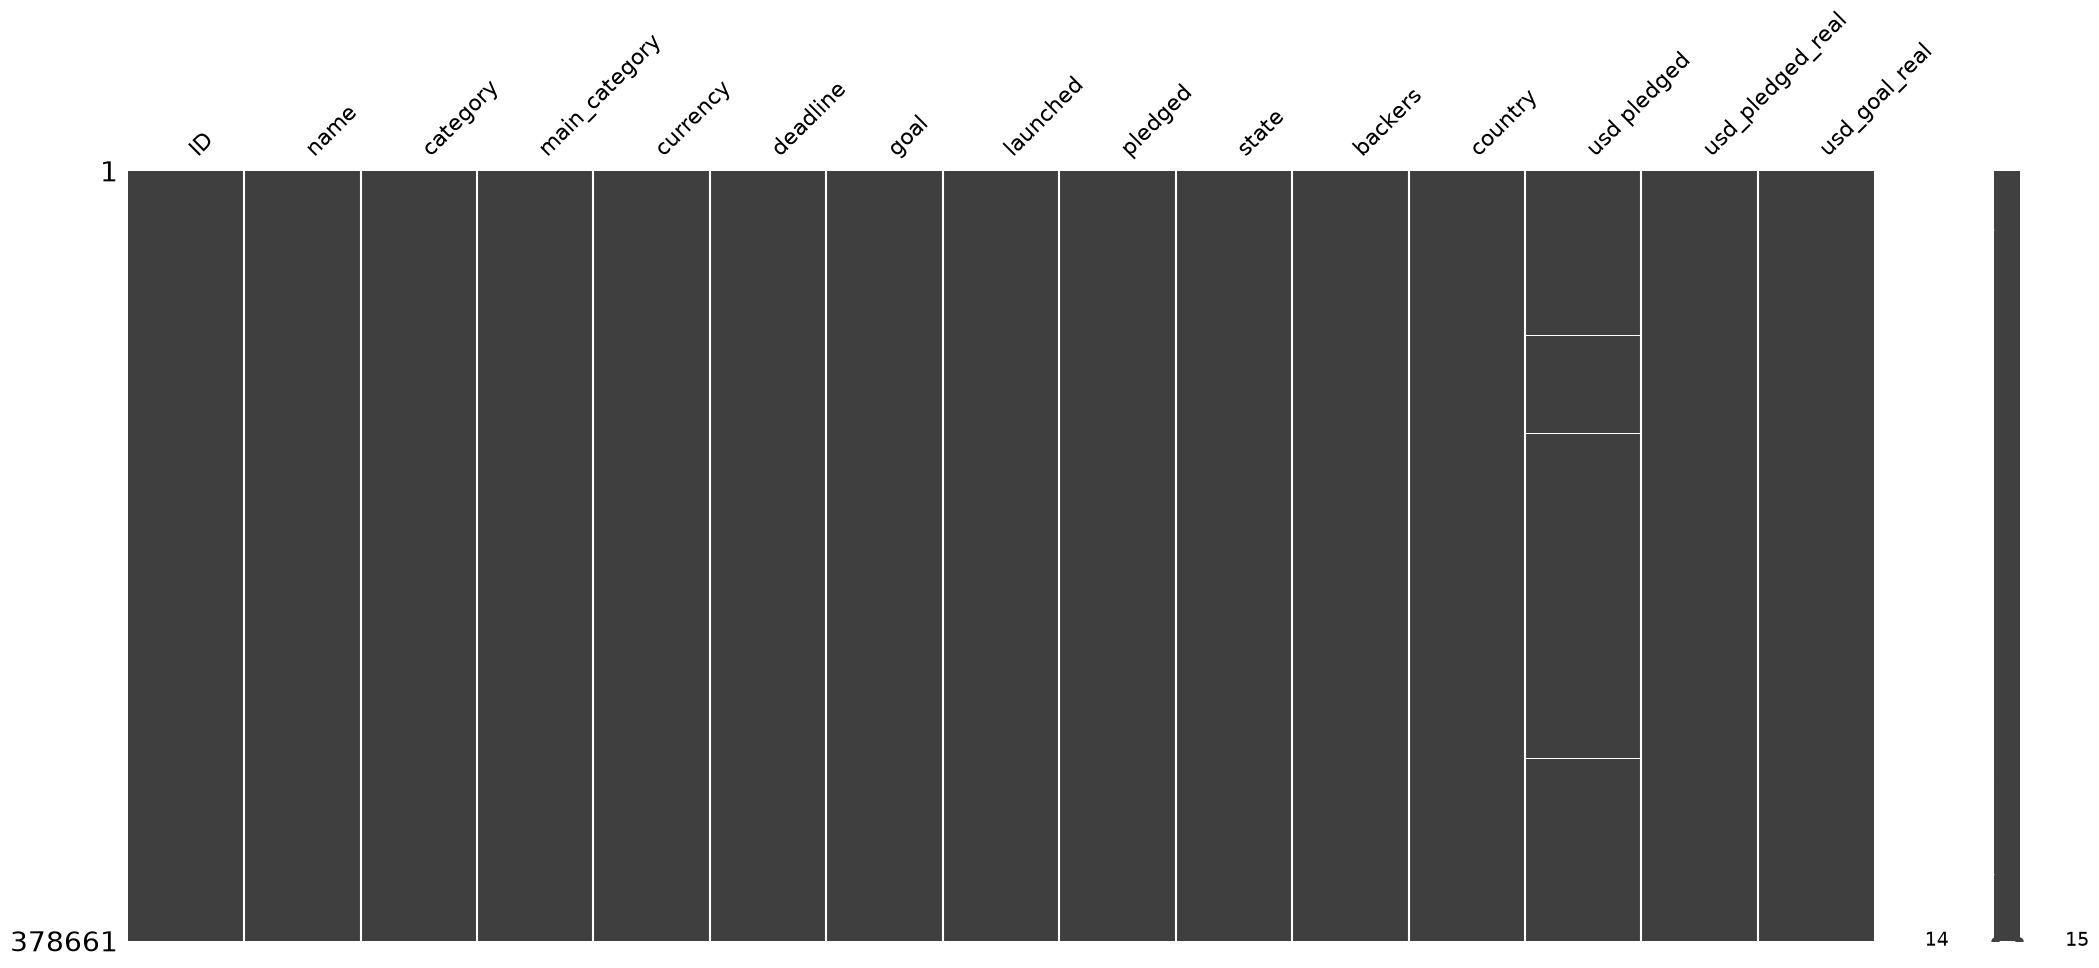

In [274]:
import missingno as msno

msno.matrix(df)
plt.show()

In [275]:
duplicate_rows = df.duplicated().sum()

print(f"Duplicate Rows: {duplicate_rows}")

Duplicate Rows: 0


In [276]:
unique_values = pd.DataFrame({
    "Unique Values": df.nunique()
})

unique_values.sort_values("Unique Values")

,Unique Values
state,6
currency,14
main_category,15
country,23
category,159
deadline,3164
backers,3963
goal,8353
usd_goal_real,50339
pledged,62130


In [277]:
constant_columns = [
    col for col in df.columns
    if df[col].nunique() == 1
]

constant_columns

[]

In [278]:
df.memory_usage(deep=True)

Index                    132
ID                   3029288
name                32113950
category            21979461
main_category       21379701
currency            19690372
deadline            22340999
goal                 3029288
launched            25748948
pledged              3029288
state               21450363
backers              3029288
country             19319305
usd pledged          3029288
usd_pledged_real     3029288
usd_goal_real        3029288
dtype: int64

In [279]:
df.memory_usage(deep=True).sum() / 1024**2

np.float64(195.72090816497803)

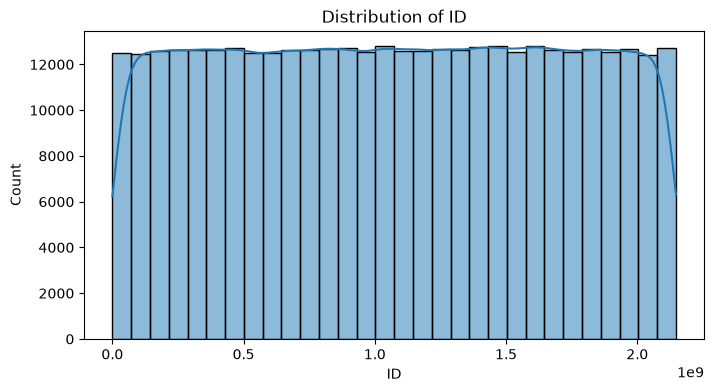

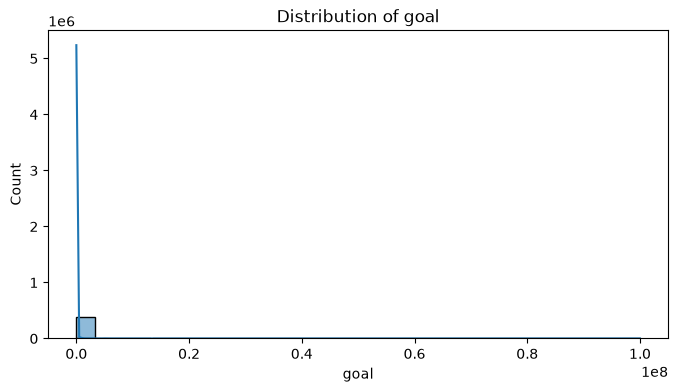

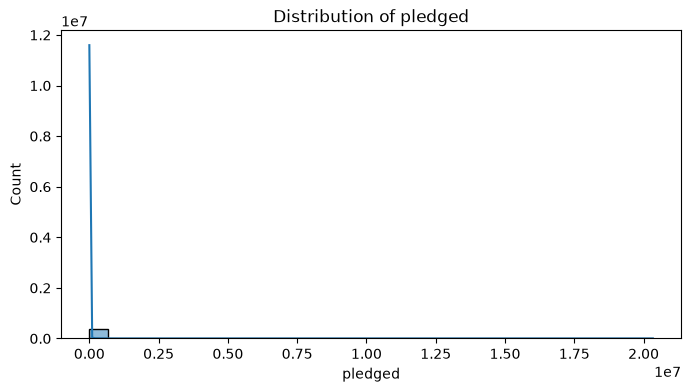

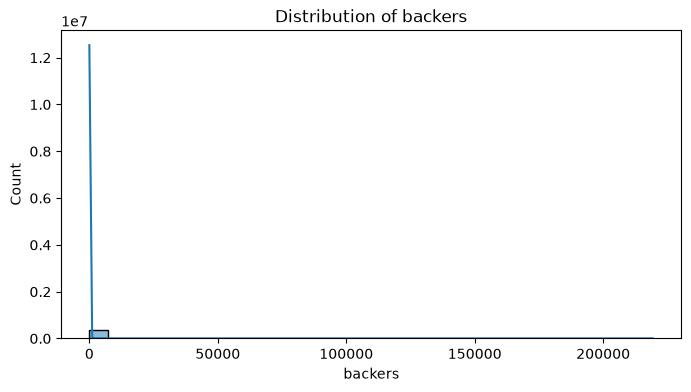

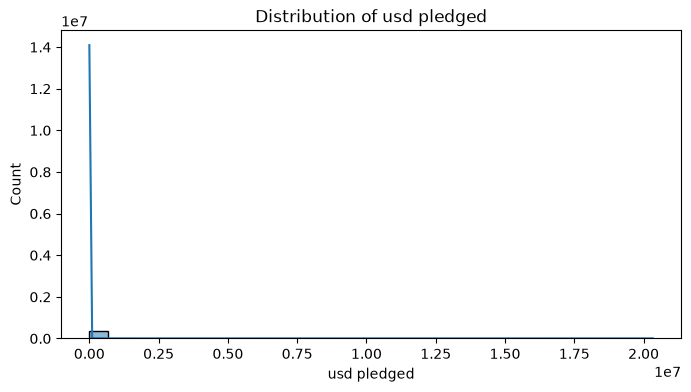

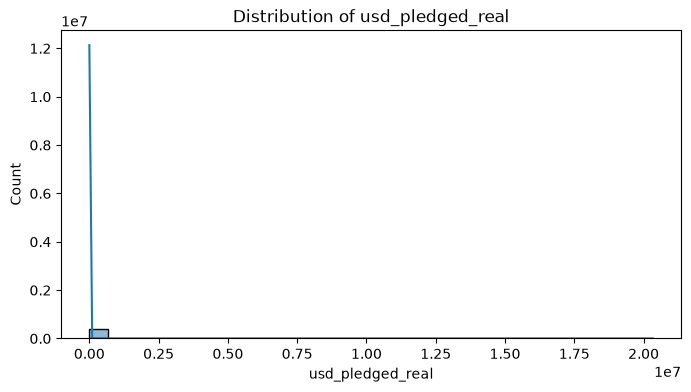

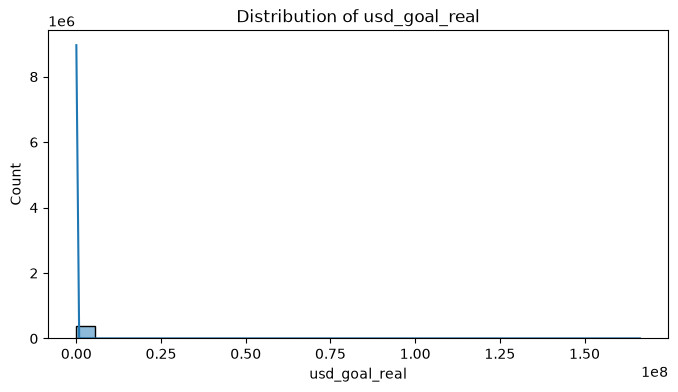

In [280]:
numeric_cols = df.select_dtypes(include=["int64", "float64"]).columns

for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[col], bins=30, kde=True)
    plt.title(f"Distribution of {col}")
    plt.show()

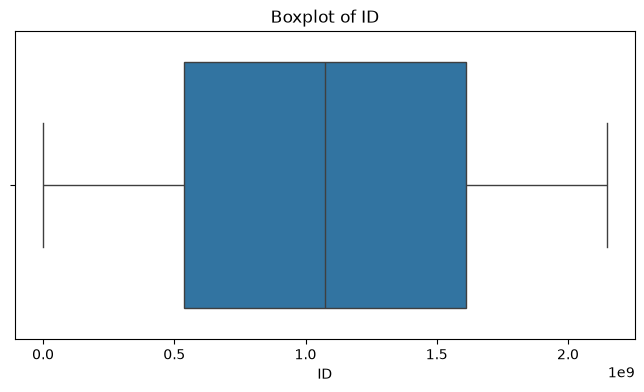

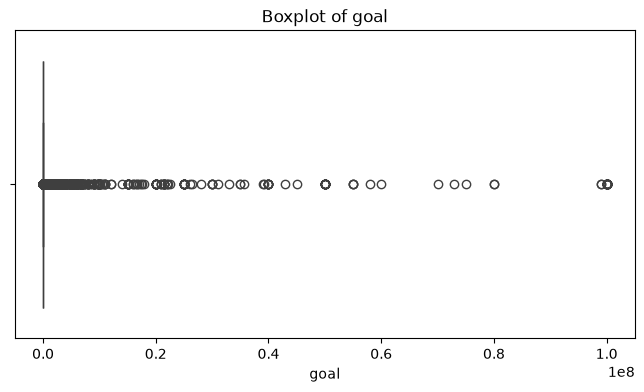

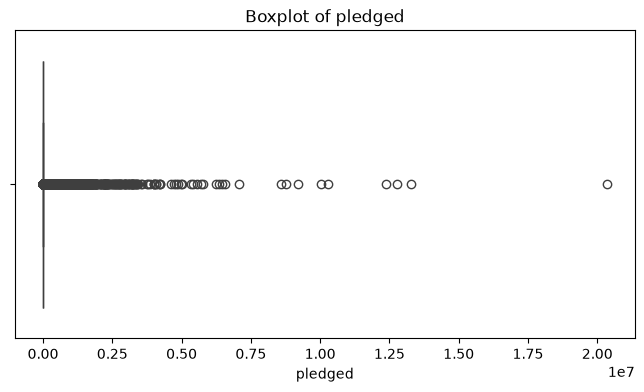

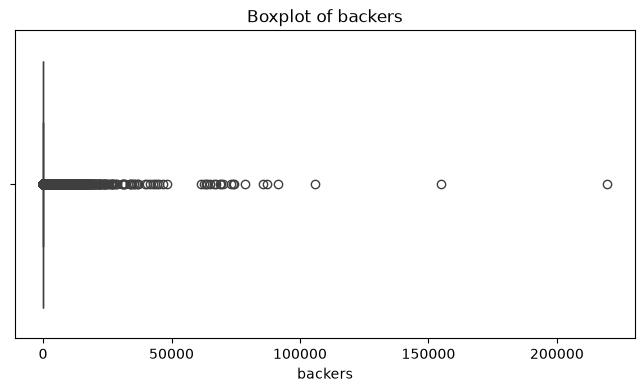

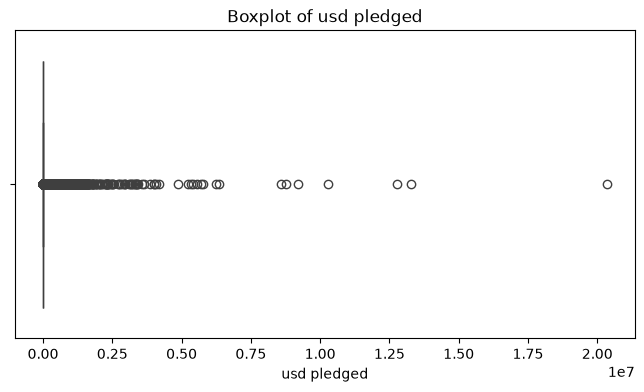

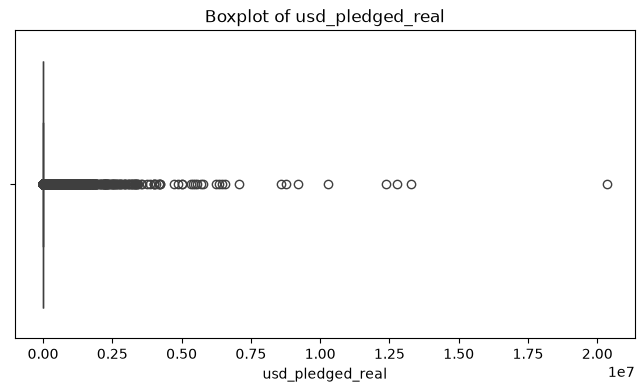

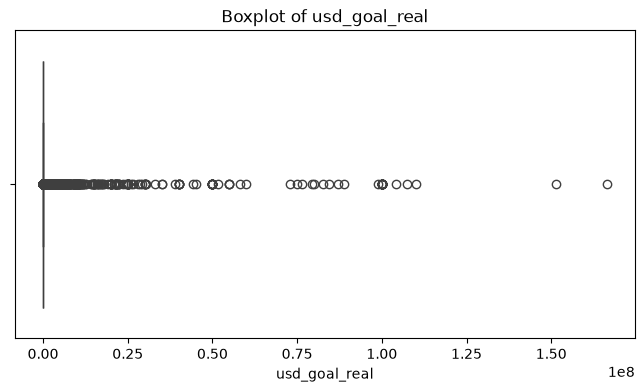

In [281]:
for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

In [282]:
df[numeric_cols].skew().sort_values()

ID                   -0.002600
goal                 70.799280
pledged              75.151792
usd_goal_real        78.220848
usd_pledged_real     82.187516
backers              86.763009
usd pledged         105.899920
dtype: float64

In [283]:
# Categorical columns
# All non-numeric columns, excluding the free-text title (`name`) and the raw date
# columns (`deadline`, `launched`) -- none of which make meaningful count plots.
exclude = ["name", "deadline", "launched"]

categorical_cols = [
    col for col in df.columns
    if col not in exclude
    and not pd.api.types.is_numeric_dtype(df[col])
]

categorical_cols

['category', 'main_category', 'currency', 'state', 'country']

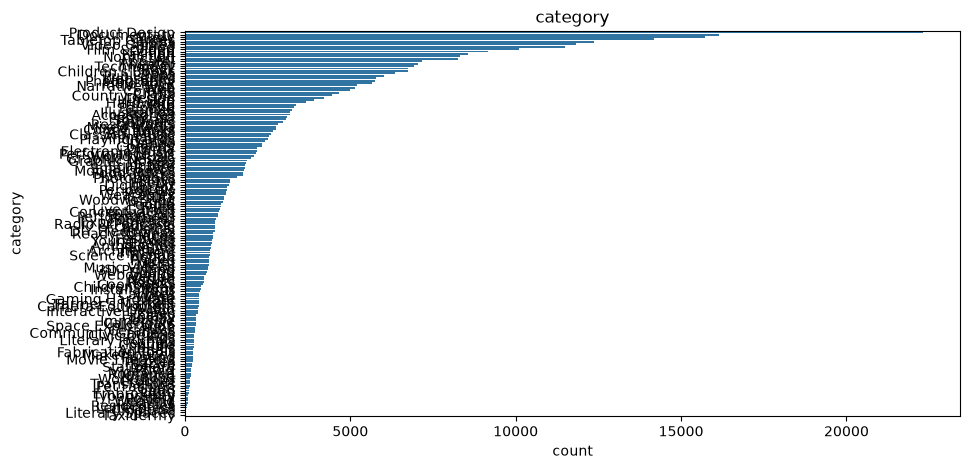

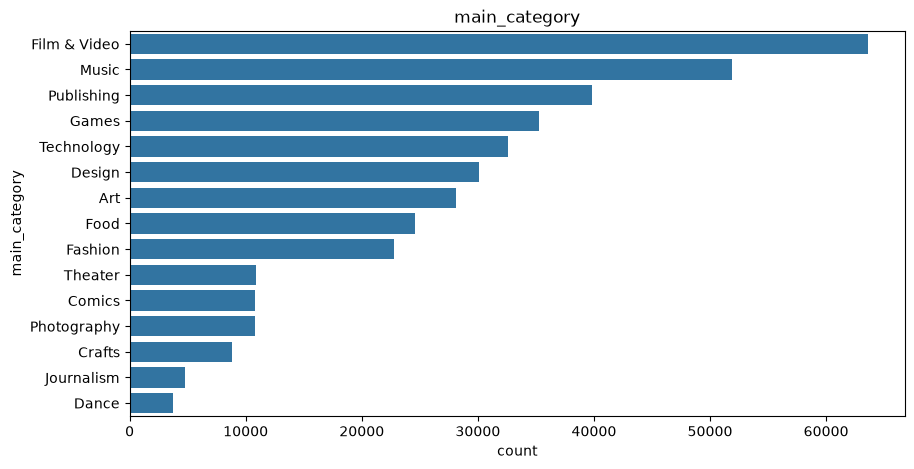

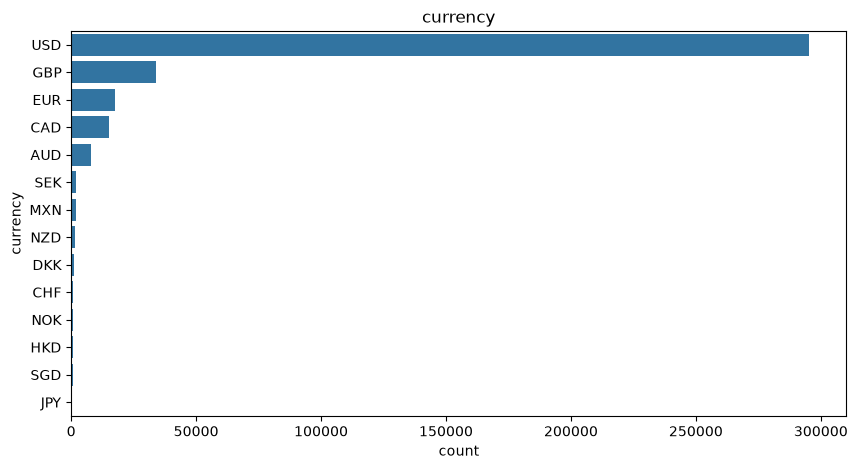

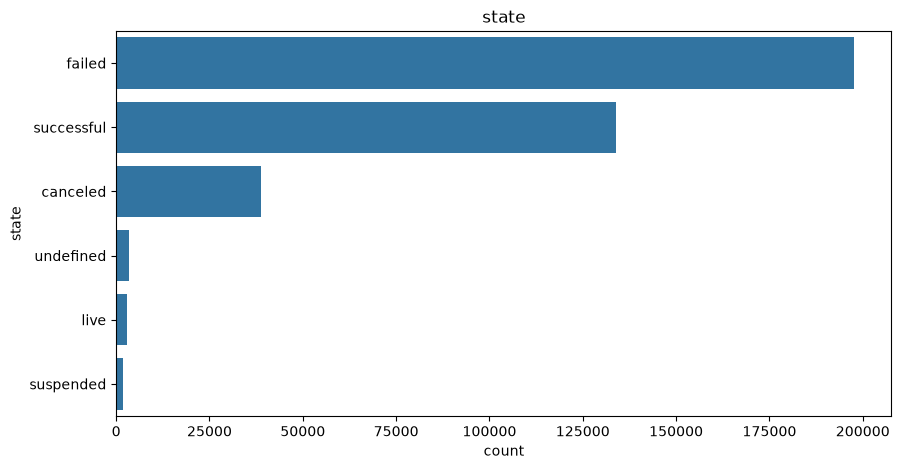

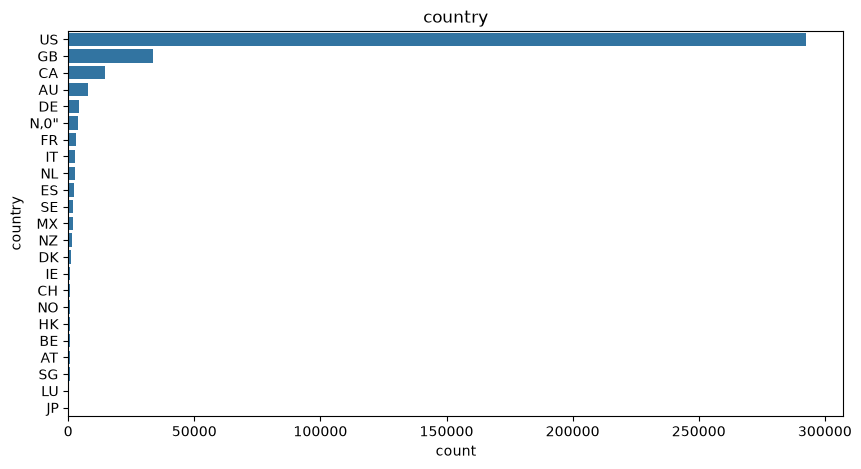

In [284]:
for col in categorical_cols:
    plt.figure(figsize=(10, 5))
    sns.countplot(y=df[col], order=df[col].value_counts().index)
    plt.title(col)
    plt.show()

In [285]:
df["category"].value_counts(normalize=True) * 100

category
Product Design     5.892870
Documentary        4.262124
Music              4.153319
Tabletop Games     3.744774
Shorts             3.263341
                     ...   
Residencies        0.018222
Letterpress        0.012940
Chiptune           0.009243
Literary Spaces    0.007130
Taxidermy          0.003433
Name: proportion, Length: 159, dtype: float64

In [286]:
df[categorical_cols].nunique()

category         159
main_category     15
currency          14
state              6
country           23
dtype: int64

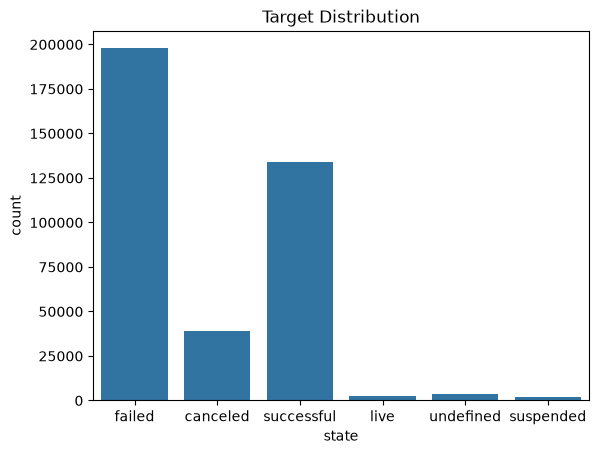

In [287]:
sns.countplot(x="state", data=df)
plt.title("Target Distribution")
plt.show()

In [288]:
df["state"].value_counts(normalize=True) * 100

state
failed        52.215306
successful    35.376234
canceled      10.241086
undefined      0.940683
live           0.739184
suspended      0.487507
Name: proportion, dtype: float64

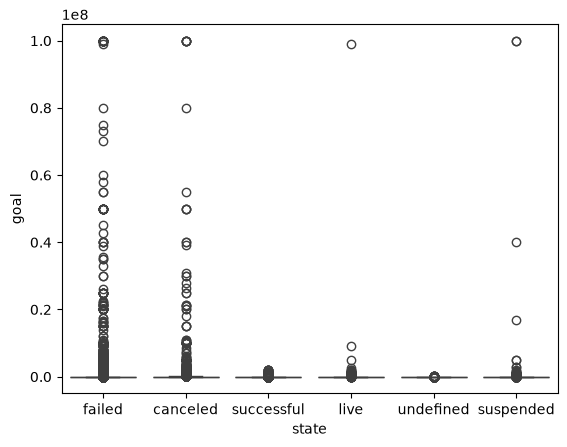

In [289]:
sns.boxplot(x="state", y="goal", data=df)
plt.show()

In [290]:
pd.crosstab(df["category"], df["state"], normalize="index")

state,canceled,failed,live,successful,suspended,undefined
category,,,,,,
3D Printing,0.133236,0.477306,0.011713,0.354319,0.021962,0.001464
Academic,0.125546,0.643013,0.012009,0.205240,0.014192,0.000000
Accessories,0.107425,0.526698,0.016746,0.339021,0.009163,0.000948
Action,0.147297,0.694595,0.009459,0.144595,0.004054,0.000000
Animals,0.070588,0.650980,0.011765,0.247059,0.019608,0.000000
...,...,...,...,...,...,...
Woodworking,0.078835,0.656384,0.009426,0.250214,0.005141,0.000000
Workshops,0.060976,0.597561,0.024390,0.304878,0.012195,0.000000
World Music,0.068030,0.484301,0.006185,0.438630,0.002854,0.000000


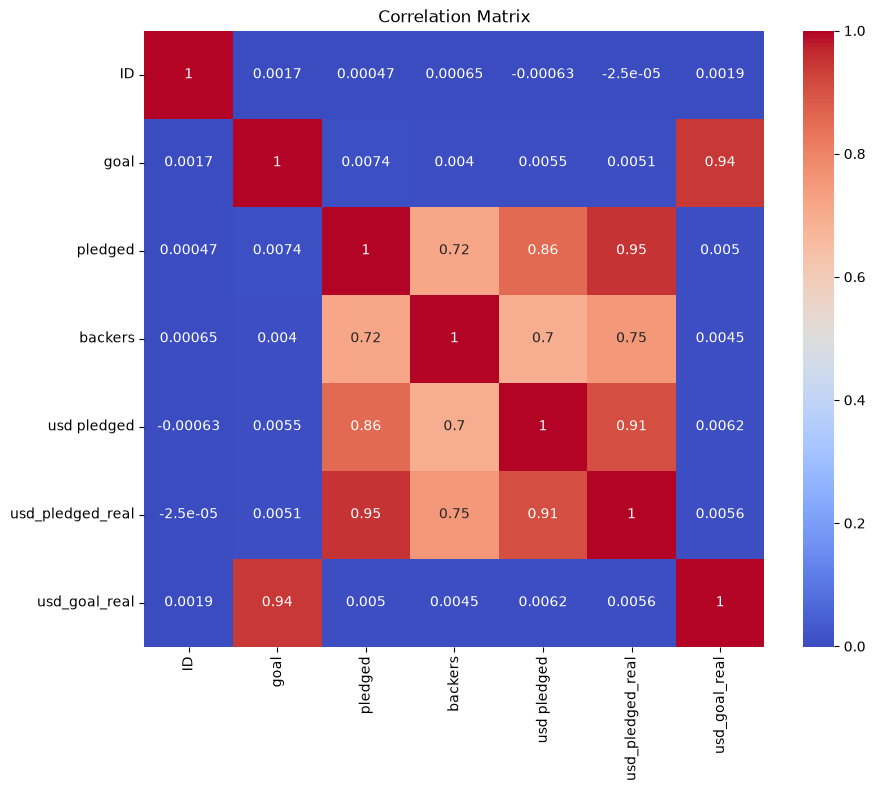

In [291]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[numeric_cols].corr(), annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

In [292]:
df["name"].isnull().sum()

np.int64(4)

In [293]:
df["name_length"] = df["name"].fillna("").apply(len)

In [294]:
df["word_count"] = df["name"].fillna("").apply(lambda x: len(x.split()))

In [ ]:
# Most common raw words in campaign titles (Week 1 NLP prep)
# Lowercase, split on whitespace, and count word frequency across all titles.
from collections import Counter

title_words = (
    df["name"]
    .fillna("")
    .str.lower()
    .str.split()
    .explode()
)

top_words = Counter(title_words).most_common(25)

top_words_df = pd.DataFrame(top_words, columns=["word", "count"])
top_words_df

In [295]:
df[numeric_cols].mean()

ID                  1.074731e+09
goal                4.908079e+04
pledged             9.682979e+03
backers             1.056175e+02
usd pledged         7.036729e+03
usd_pledged_real    9.058924e+03
usd_goal_real       4.545440e+04
dtype: float64

In [296]:
df[numeric_cols].median()

ID                  1.075276e+09
goal                5.200000e+03
pledged             6.200000e+02
backers             1.200000e+01
usd pledged         3.947200e+02
usd_pledged_real    6.243300e+02
usd_goal_real       5.500000e+03
dtype: float64

In [297]:
df[numeric_cols].mode().iloc[0]

ID                  5971.0
goal                5000.0
pledged                0.0
backers                0.0
usd pledged            0.0
usd_pledged_real       0.0
usd_goal_real       5000.0
Name: 0, dtype: float64

In [298]:
df[categorical_cols].mode().iloc[0]

category         Product Design
main_category      Film & Video
currency                    USD
state                    failed
country                      US
Name: 0, dtype: str

In [299]:
df[numeric_cols].var()

ID                  3.832677e+17
goal                1.400415e+12
pledged             9.146246e+09
backers             8.229847e+05
usd pledged         6.184210e+09
usd_pledged_real    8.276149e+09
usd_goal_real       1.329294e+12
dtype: float64

In [300]:
df[numeric_cols].std()

ID                  6.190862e+08
goal                1.183391e+06
pledged             9.563601e+04
backers             9.071850e+02
usd pledged         7.863975e+04
usd_pledged_real    9.097334e+04
usd_goal_real       1.152950e+06
dtype: float64

In [301]:
df[numeric_cols].quantile([0.25, 0.50, 0.75]).T

,0.25,0.50,0.75
ID,5.382635e+08,1.075276e+09,1.610149e+09
goal,2.000000e+03,5.200000e+03,1.600000e+04
pledged,3.000000e+01,6.200000e+02,4.076000e+03
backers,2.000000e+00,1.200000e+01,5.600000e+01
usd pledged,1.698000e+01,3.947200e+02,3.034090e+03
usd_pledged_real,3.100000e+01,6.243300e+02,4.050000e+03
usd_goal_real,2.000000e+03,5.500000e+03,1.550000e+04


In [302]:
df[numeric_cols].quantile([0.01, 0.05, 0.95, 0.99]).T

,0.01,0.05,0.95,0.99
ID,21802975.6,108769050.0,2.039733e+09,2.125552e+09
goal,75.0,400.0,9.000000e+04,4.000000e+05
pledged,0.0,0.0,2.958100e+04,1.348307e+05
backers,0.0,0.0,3.340000e+02,1.506000e+03
usd pledged,0.0,0.0,2.243285e+04,9.624458e+04
usd_pledged_real,0.0,0.0,2.809000e+04,1.226284e+05
usd_goal_real,75.0,400.0,8.000000e+04,3.382241e+05


In [303]:
df[numeric_cols].skew()


ID                   -0.002600
goal                 70.799280
pledged              75.151792
backers              86.763009
usd pledged         105.899920
usd_pledged_real     82.187516
usd_goal_real        78.220848
dtype: float64

In [304]:
df[numeric_cols].kurt()

ID                     -1.197962
goal                 5574.951599
pledged             10010.262480
backers             13954.938078
usd pledged         18960.922143
usd_pledged_real    11796.481939
usd_goal_real        7082.887238
dtype: float64

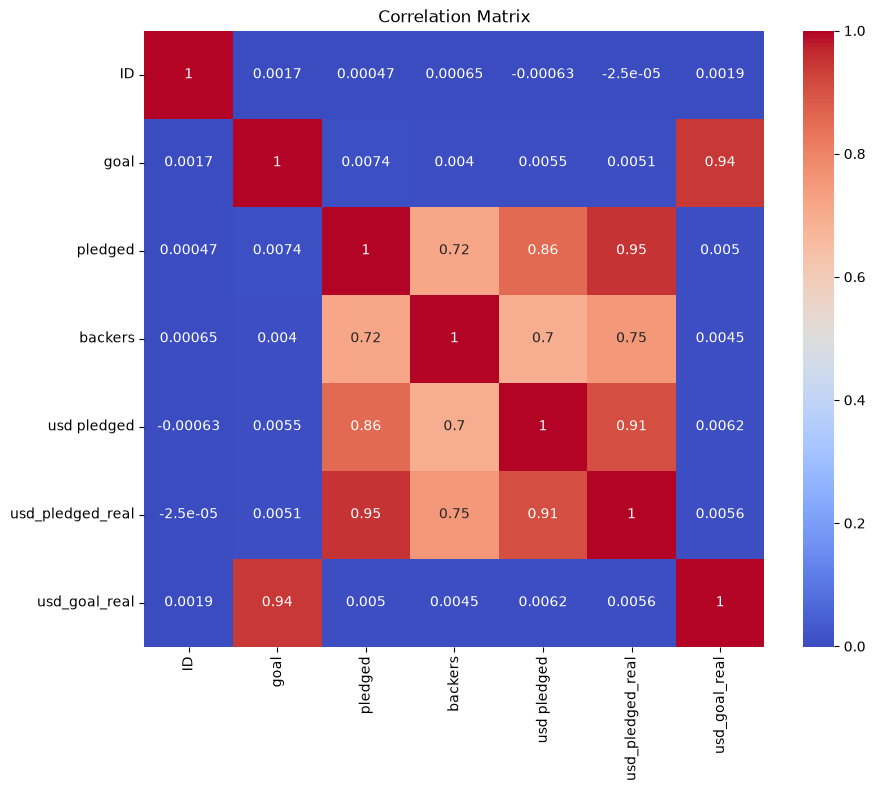

In [305]:
corr = df[numeric_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.title("Correlation Matrix")
plt.show()

In [306]:
df

,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,usd_pledged_real,usd_goal_real,name_length,word_count
0,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09,1000.0,2015-08-11 12:12:28,0.0,failed,0,GB,0.0,0.0,1533.95,31,6
1,1000003930,Greeting From Earth: ZGAC Arts Capsule For ET,Narrative Film,Film & Video,USD,2017-11-01,30000.0,2017-09-02 04:43:57,2421.0,failed,15,US,100.0,2421.0,30000.00,45,8
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26,45000.0,2013-01-12 00:20:50,220.0,failed,3,US,220.0,220.0,45000.00,14,3
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16,5000.0,2012-03-17 03:24:11,1.0,failed,1,US,1.0,1.0,5000.00,49,7
4,1000011046,Community Film Project: The Art of Neighborhood Filmmaking,Film & Video,Film & Video,USD,2015-08-29,19500.0,2015-07-04 08:35:03,1283.0,canceled,14,US,1283.0,1283.0,19500.00,58,8
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
378656,999976400,ChknTruk Nationwide Charity Drive 2014 (Canceled),Documentary,Film & Video,USD,2014-10-17,50000.0,2014-09-17 02:35:30,25.0,canceled,1,US,25.0,25.0,50000.00,49,6
378657,999977640,The Tribe,Narrative Film,Film & Video,USD,2011-07-19,1500.0,2011-06-22 03:35:14,155.0,failed,5,US,155.0,155.0,1500.00,9,2
378658,999986353,Walls of Remedy- New lesbian Romantic Comedy feature unlike any other!!,Narrative Film,Film & Video,USD,2010-08-16,15000.0,2010-07-01 19:40:30,20.0,failed,1,US,20.0,20.0,15000.00,71,11
378659,999987933,BioDefense Education Kit,Technology,Technology,USD,2016-02-13,15000.0,2016-01-13 18:13:53,200.0,failed,6,US,200.0,200.0,15000.00,24,3


In [307]:
# Encode the target numerically: successful = 1, failed = 0
df["is_successful"] = (df["state"] == "successful").astype(int)

# Clean binary target: keep only decided campaigns (successful / failed),
# dropping the ~12% ambiguous states (canceled, live, undefined, suspended)
decided = df[df["state"].isin(["successful", "failed"])]

# Numeric features to rank, excluding the meaningless ID
feature_cols = [col for col in numeric_cols if col != "ID"]

# Correlation of numeric features with the encoded target
corr_with_target = decided[feature_cols + ["is_successful"]].corr()
corr_with_target["is_successful"].sort_values(ascending=False)

is_successful       1.000000
backers             0.125790
pledged             0.109507
usd_pledged_real    0.108298
usd pledged         0.095658
usd_goal_real      -0.023735
goal               -0.025099
Name: is_successful, dtype: float64

In [308]:
# Numeric success target on the full frame: successful = 1, everything else = 0
# (used by the success-rate analyses in Parts A-G below)
df["target"] = (df["state"] == "successful").astype(int)

In [309]:
category_success = (
    df.groupby("category")["state"]
      .value_counts(normalize=True)
      .rename("proportion")
      .reset_index()
)

In [310]:
df_analysis = df[df["state"].isin(["successful", "failed"])].copy()

df_analysis["target"] = (
    df_analysis["state"] == "successful"
).astype(int)

category_success = (
    df_analysis
        .groupby("category")["target"]
        .mean()
        .sort_values(ascending=False)
)

category_success.head(10)

category
Chiptune           0.818182
Residencies        0.735294
Anthologies        0.706920
Dance              0.695221
Literary Spaces    0.684211
Indie Rock         0.678927
Classical Music    0.675000
Letterpress        0.673913
Tabletop Games     0.669789
Country & Folk     0.667458
Name: target, dtype: float64

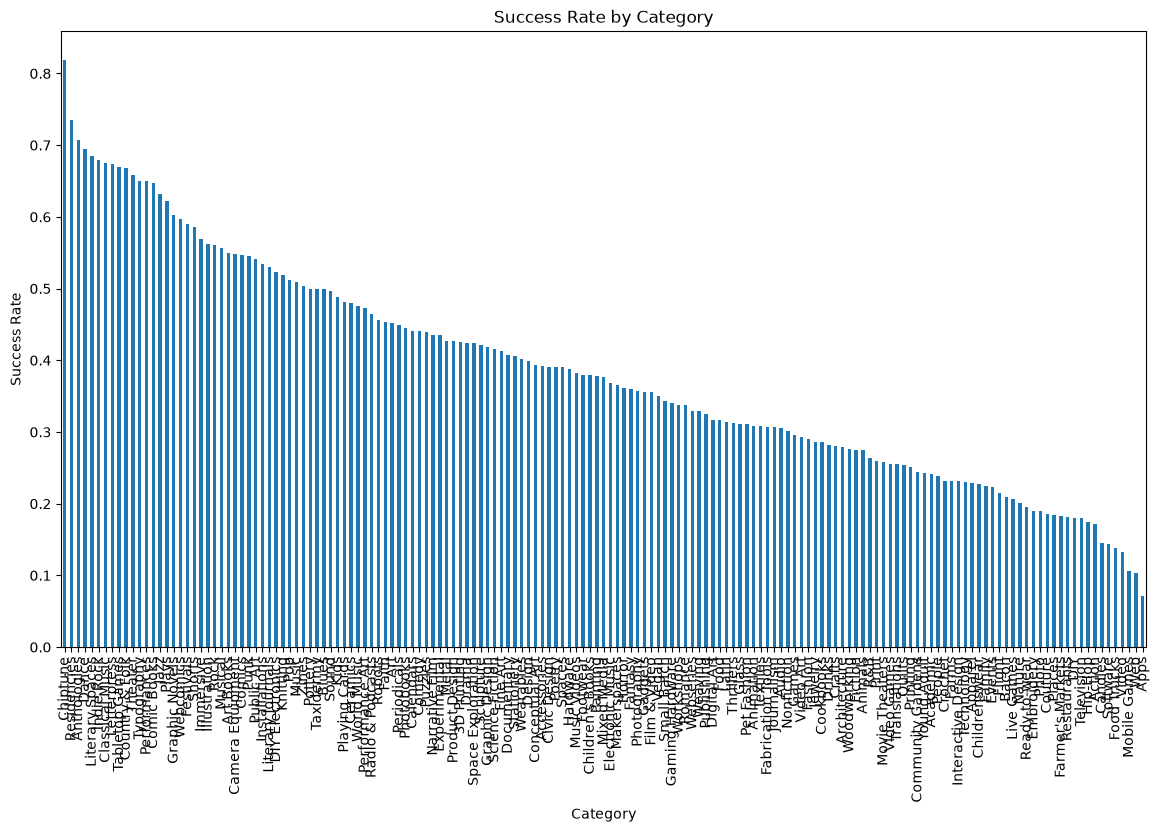

In [311]:
plt.figure(figsize=(14,8))

category_success.plot(kind="bar")

plt.title("Success Rate by Category")

plt.ylabel("Success Rate")

plt.xlabel("Category")

plt.xticks(rotation=90)

plt.show()

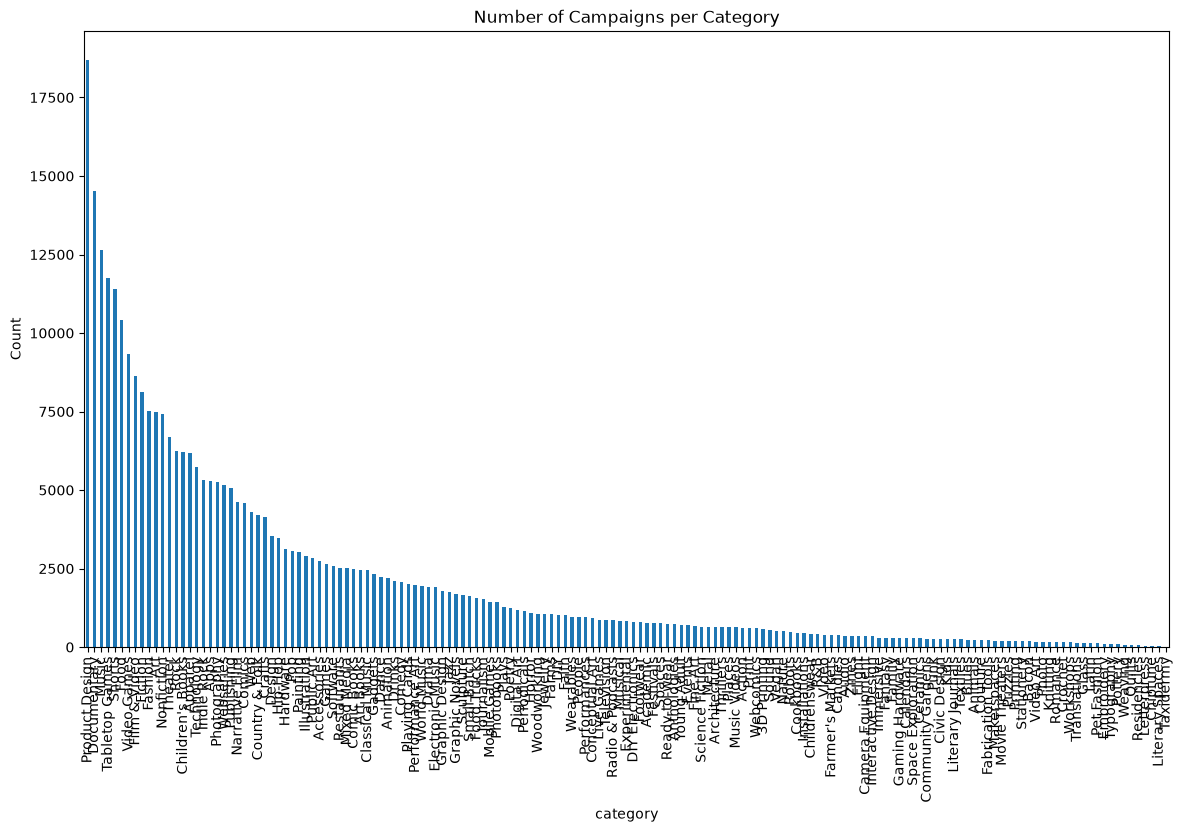

In [312]:
category_counts = (
    df_analysis["category"]
    .value_counts()
)

plt.figure(figsize=(14,8))

category_counts.plot(kind="bar")

plt.title("Number of Campaigns per Category")

plt.ylabel("Count")

plt.show()

In [313]:
category_summary = (
    df_analysis
    .groupby("category")
    .agg(
        Campaigns=("target","count"),
        Success_Rate=("target","mean")
    )
    .sort_values(
        "Success_Rate",
        ascending=False
    )
)

category_summary.head(20)

,Campaigns,Success_Rate
category,,
Chiptune,33,0.818182
Residencies,68,0.735294
Anthologies,737,0.706920
Dance,2218,0.695221
Literary Spaces,19,0.684211
Indie Rock,5329,0.678927
Classical Music,2440,0.675000
Letterpress,46,0.673913
Tabletop Games,11744,0.669789


In [314]:
df["goal"].describe()

count    3.786610e+05
mean     4.908079e+04
std      1.183391e+06
min      1.000000e-02
25%      2.000000e+03
50%      5.200000e+03
75%      1.600000e+04
max      1.000000e+08
Name: goal, dtype: float64

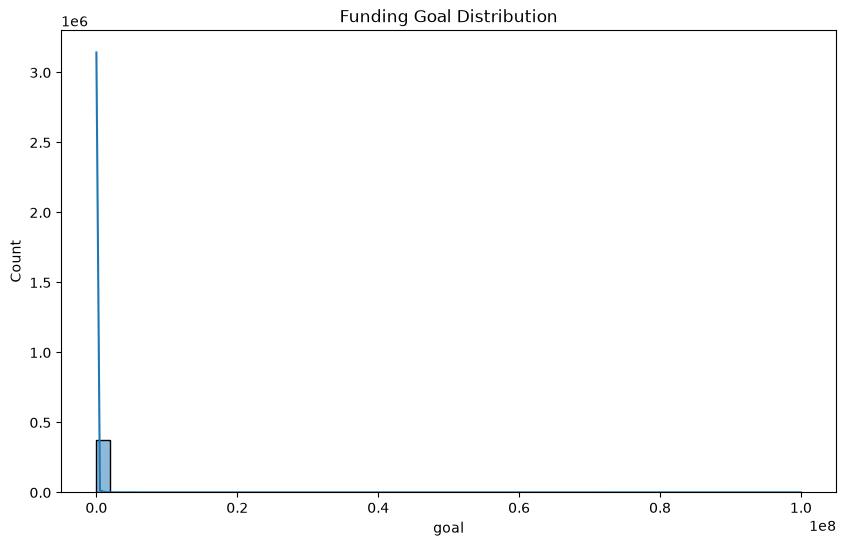

In [315]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=df,
    x="goal",
    bins=50,
    kde=True
)

plt.title("Funding Goal Distribution")

plt.show()

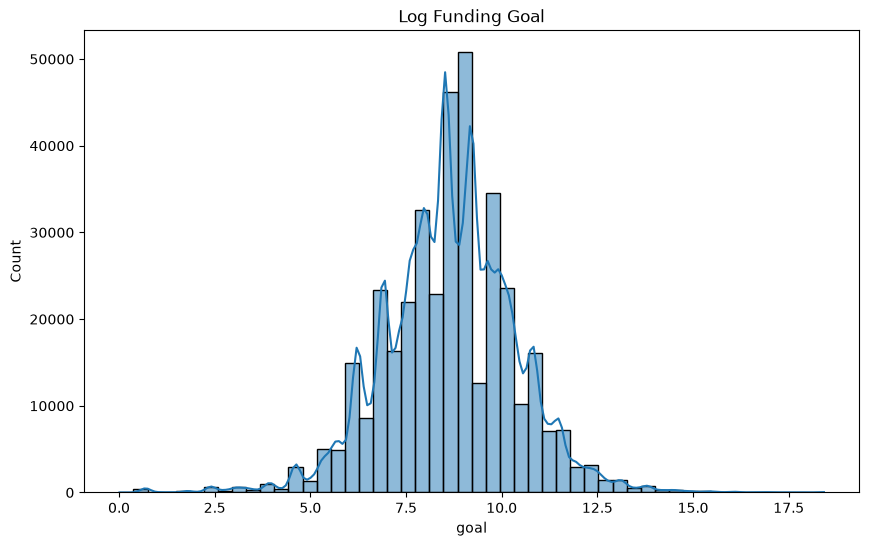

In [316]:
plt.figure(figsize=(10,6))

sns.histplot(
    np.log1p(df["goal"]),
    bins=50,
    kde=True
)

plt.title("Log Funding Goal")

plt.show()

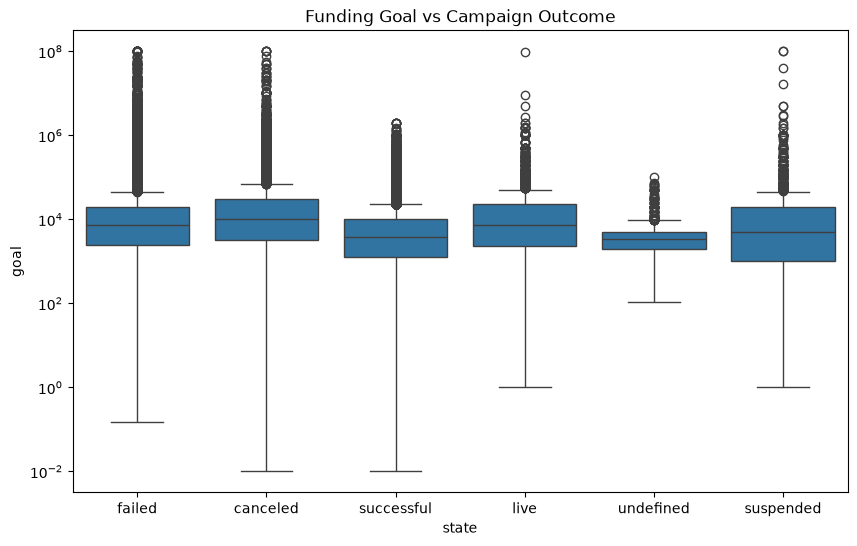

In [317]:
plt.figure(figsize=(10,6))

sns.boxplot(
    x="state",
    y="goal",
    data=df
)

plt.yscale("log")

plt.title("Funding Goal vs Campaign Outcome")

plt.show()

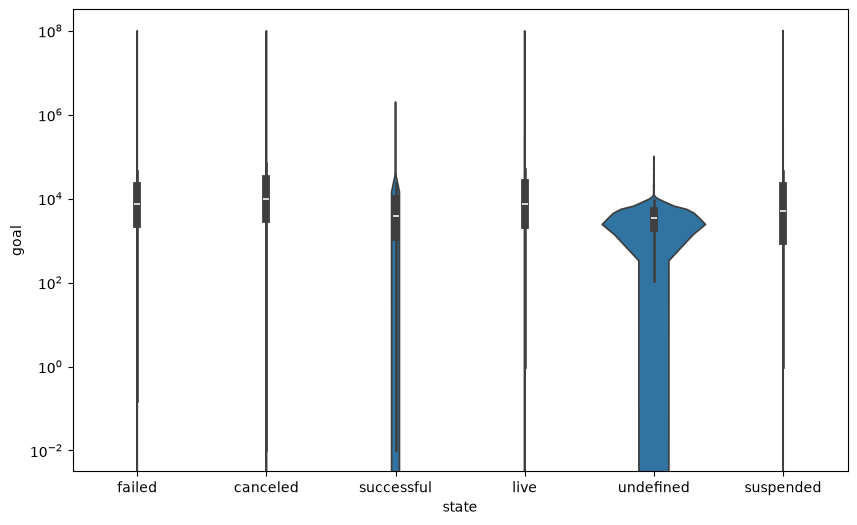

In [318]:
plt.figure(figsize=(10,6))

sns.violinplot(
    x="state",
    y="goal",
    data=df
)

plt.yscale("log")

plt.show()

In [319]:
goal_summary = (
    df
    .groupby("state")["goal"]
    .describe()
)

goal_summary

,count,mean,std,min,25%,50%,75%,max
state,,,,,,,,
canceled,38779.0,86193.059649,1.470051e+06,0.01,3285.0,10000.0,30000.0,100000000.0
failed,197719.0,67346.845539,1.447227e+06,0.15,2500.0,7500.0,20000.0,100000000.0
live,2799.0,76762.393355,1.885400e+06,1.00,2400.0,7500.0,23215.0,99000000.0
successful,133956.0,10162.960544,3.124829e+04,0.01,1250.0,3923.0,10000.0,2000000.0
suspended,1846.0,181370.796858,3.447274e+06,1.00,1000.0,5000.0,20000.0,100000000.0
undefined,3562.0,4405.393599,4.799354e+03,108.00,2000.0,3500.0,5000.0,100000.0


In [320]:
goal_bins = [
    0,
    1000,
    5000,
    10000,
    50000,
    100000,
    500000,
    np.inf
]

goal_labels = [
    "0-1K",
    "1K-5K",
    "5K-10K",
    "10K-50K",
    "50K-100K",
    "100K-500K",
    "500K+"
]

df["goal_bucket"] = pd.cut(
    df["goal"],
    bins=goal_bins,
    labels=goal_labels
)

In [321]:
df

,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,usd_pledged_real,usd_goal_real,name_length,word_count,is_successful,target,goal_bucket
0,1000002330,The Songs of Adelaide & Abullah,Poetry,Publishing,GBP,2015-10-09,1000.0,2015-08-11 12:12:28,0.0,failed,0,GB,0.0,0.0,1533.95,31,6,0,0,0-1K
1,1000003930,Greeting From Earth: ZGAC Arts Capsule For ET,Narrative Film,Film & Video,USD,2017-11-01,30000.0,2017-09-02 04:43:57,2421.0,failed,15,US,100.0,2421.0,30000.00,45,8,0,0,10K-50K
2,1000004038,Where is Hank?,Narrative Film,Film & Video,USD,2013-02-26,45000.0,2013-01-12 00:20:50,220.0,failed,3,US,220.0,220.0,45000.00,14,3,0,0,10K-50K
3,1000007540,ToshiCapital Rekordz Needs Help to Complete Album,Music,Music,USD,2012-04-16,5000.0,2012-03-17 03:24:11,1.0,failed,1,US,1.0,1.0,5000.00,49,7,0,0,1K-5K
4,1000011046,Community Film Project: The Art of Neighborhood Filmmaking,Film & Video,Film & Video,USD,2015-08-29,19500.0,2015-07-04 08:35:03,1283.0,canceled,14,US,1283.0,1283.0,19500.00,58,8,0,0,10K-50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
378656,999976400,ChknTruk Nationwide Charity Drive 2014 (Canceled),Documentary,Film & Video,USD,2014-10-17,50000.0,2014-09-17 02:35:30,25.0,canceled,1,US,25.0,25.0,50000.00,49,6,0,0,10K-50K
378657,999977640,The Tribe,Narrative Film,Film & Video,USD,2011-07-19,1500.0,2011-06-22 03:35:14,155.0,failed,5,US,155.0,155.0,1500.00,9,2,0,0,1K-5K
378658,999986353,Walls of Remedy- New lesbian Romantic Comedy feature unlike any other!!,Narrative Film,Film & Video,USD,2010-08-16,15000.0,2010-07-01 19:40:30,20.0,failed,1,US,20.0,20.0,15000.00,71,11,0,0,10K-50K
378659,999987933,BioDefense Education Kit,Technology,Technology,USD,2016-02-13,15000.0,2016-01-13 18:13:53,200.0,failed,6,US,200.0,200.0,15000.00,24,3,0,0,10K-50K


In [322]:
bucket_summary = (
    df
    .groupby("goal_bucket")["target"]
    .mean()
)

bucket_summary

goal_bucket
0-1K         0.487279
1K-5K        0.413069
5K-10K       0.344940
10K-50K      0.266396
50K-100K     0.143236
100K-500K    0.082268
500K+        0.023520
Name: target, dtype: float64

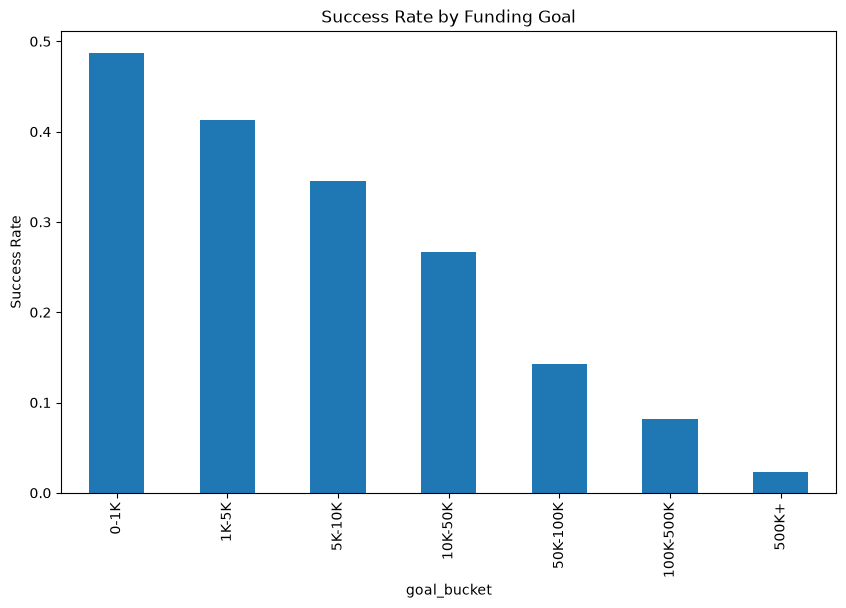

In [323]:
bucket_summary.plot(
    kind="bar",
    figsize=(10,6)
)

plt.ylabel("Success Rate")

plt.title("Success Rate by Funding Goal")

plt.show()

In [324]:
df["goal"].quantile(
    [0.25,0.50,0.75,0.90,0.95,0.99]
)

0.25      2000.0
0.50      5200.0
0.75     16000.0
0.90     50000.0
0.95     90000.0
0.99    400000.0
Name: goal, dtype: float64

In [325]:
top_goals = (
    df
    .sort_values(
        "goal",
        ascending=False
    )
    .head(20)
)

top_goals

,ID,name,category,main_category,currency,deadline,goal,launched,pledged,state,backers,country,usd pledged,usd_pledged_real,usd_goal_real,name_length,word_count,is_successful,target,goal_bucket
348139,843636303,"The Exodus, one Ark or many.",Documentary,Film & Video,USD,2016-08-16,100000000.0,2016-06-17 17:20:52,14.0,failed,5,US,0.00,14.00,1.000000e+08,28,6,0,0,500K+
367928,944541075,Hydroponic's Skyscraper(un gratte-ciel hydroponique)e-solar,Technology,Technology,EUR,2015-10-24,100000000.0,2015-08-25 23:52:30,2.0,failed,2,FR,2.29,2.20,1.101698e+08,59,4,0,0,500K+
118402,1601563193,Our future,Space Exploration,Technology,AUD,2014-10-07,100000000.0,2014-08-08 19:05:39,1.0,failed,1,AU,0.93,0.87,8.709284e+07,10,2,0,0,500K+
300797,601594365,The Multi-Trillion Dollar Dream™ (Canceled),Architecture,Design,USD,2015-03-02,100000000.0,2015-01-07 19:11:05,1.0,canceled,1,US,1.00,1.00,1.000000e+08,43,5,0,0,500K+
55009,1279992058,Kybernan Holographic Gaming Network,Video Games,Games,USD,2016-01-01,100000000.0,2015-11-07 00:57:17,13.0,failed,4,US,13.00,13.00,1.000000e+08,35,4,0,0,500K+
95513,1485385229,This Land Called America,Drama,Film & Video,SEK,2017-09-03,100000000.0,2017-07-05 18:29:55,227.0,failed,3,SE,0.00,28.70,1.264302e+07,24,4,0,0,500K+
369688,953415668,Currency Free System,Software,Technology,MXN,2017-03-22,100000000.0,2017-03-01 14:09:37,10.0,failed,1,MX,0.00,0.53,5.289326e+06,20,3,0,0,500K+
72775,1370542565,Art Is Fabulous,Art,Art,USD,2016-06-05,100000000.0,2016-04-06 02:55:07,115.0,failed,2,US,115.00,115.00,1.000000e+08,15,3,0,0,500K+
278601,487345242,Billionaire Boy Blog (Canceled),Young Adult,Publishing,DKK,2015-03-15,100000000.0,2015-02-13 06:45:00,0.0,canceled,0,DK,0.00,0.00,1.446132e+07,31,4,0,0,500K+
243435,308045282,Jesus Priest,Action,Film & Video,CAD,2015-05-04,100000000.0,2015-03-05 22:57:11,1.0,failed,1,CA,0.80,0.83,8.262414e+07,12,2,0,0,500K+


In [326]:
df["launched"] = pd.to_datetime(df["launched"])
df["deadline"] = pd.to_datetime(df["deadline"])

In [327]:
df[["launched", "deadline"]].dtypes

launched    datetime64[us]
deadline    datetime64[us]
dtype: object

In [328]:
df["campaign_duration"] = (
    df["deadline"] - df["launched"]
).dt.days

In [329]:
df["campaign_duration"].describe()

count    378661.000000
mean         33.481122
std          65.909172
min           0.000000
25%          29.000000
50%          29.000000
75%          36.000000
max       16738.000000
Name: campaign_duration, dtype: float64

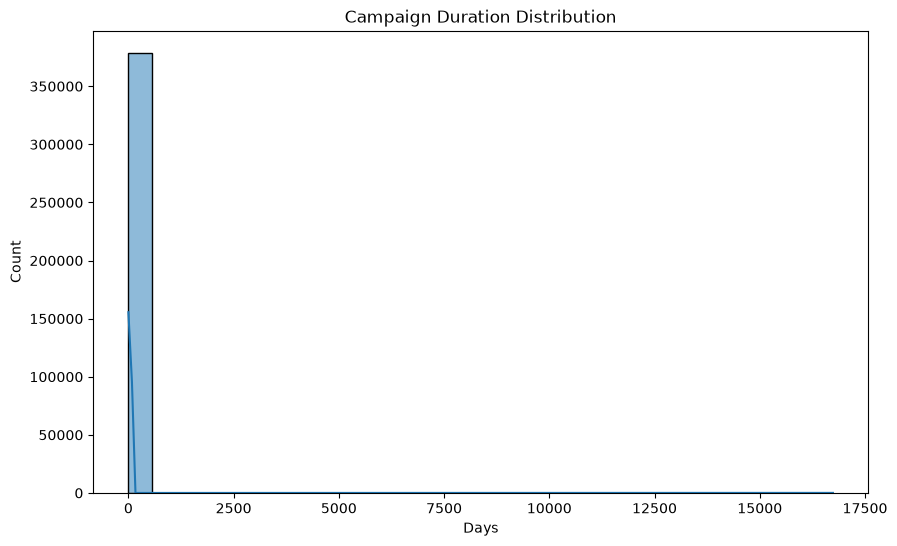

In [330]:
plt.figure(figsize=(10,6))

sns.histplot(
    data=df,
    x="campaign_duration",
    bins=30,
    kde=True
)

plt.title("Campaign Duration Distribution")

plt.xlabel("Days")

plt.show()

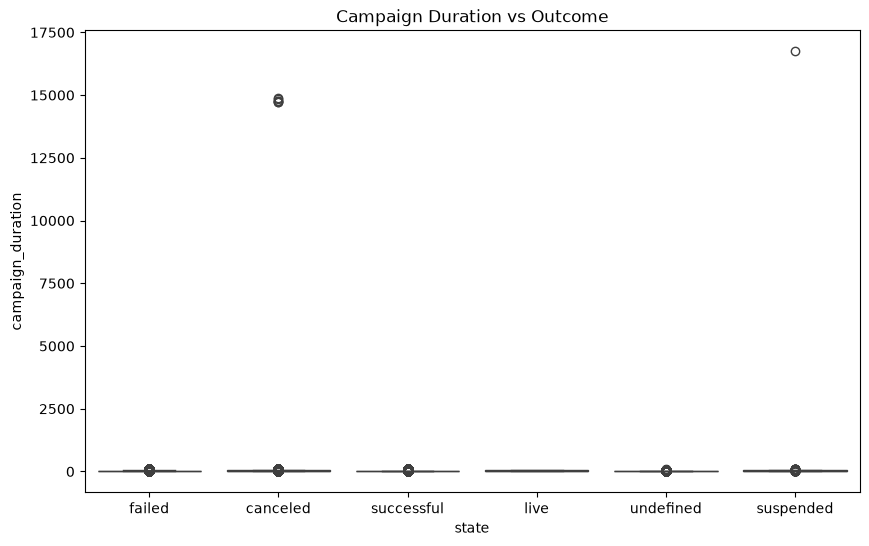

In [331]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=df,
    x="state",
    y="campaign_duration"
)

plt.title("Campaign Duration vs Outcome")

plt.show()

In [332]:
duration_bins = [0, 15, 30, 45, 60, 90, np.inf]

duration_labels = [
    "0-15",
    "15-30",
    "30-45",
    "45-60",
    "60-90",
    "90+"
]

df["duration_bucket"] = pd.cut(
    df["campaign_duration"],
    bins=duration_bins,
    labels=duration_labels
)

In [333]:
duration_summary = (
    df
    .groupby("duration_bucket")["target"]
    .mean()
)

duration_summary

duration_bucket
0-15     0.468222
15-30    0.359909
30-45    0.389229
45-60    0.223715
60-90    0.337103
90+      0.172414
Name: target, dtype: float64

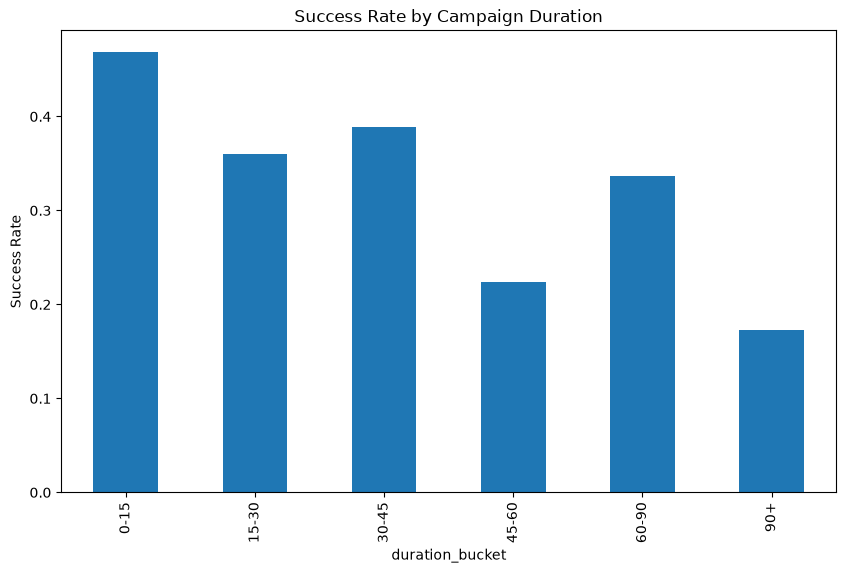

In [334]:
duration_summary.plot(
    kind="bar",
    figsize=(10,6)
)

plt.ylabel("Success Rate")

plt.title("Success Rate by Campaign Duration")

plt.show()

In [335]:
df["launch_month"] = (
    df["launched"]
      .dt.month_name()
)

In [336]:
df["launch_month_num"] = (
    df["launched"]
      .dt.month
)

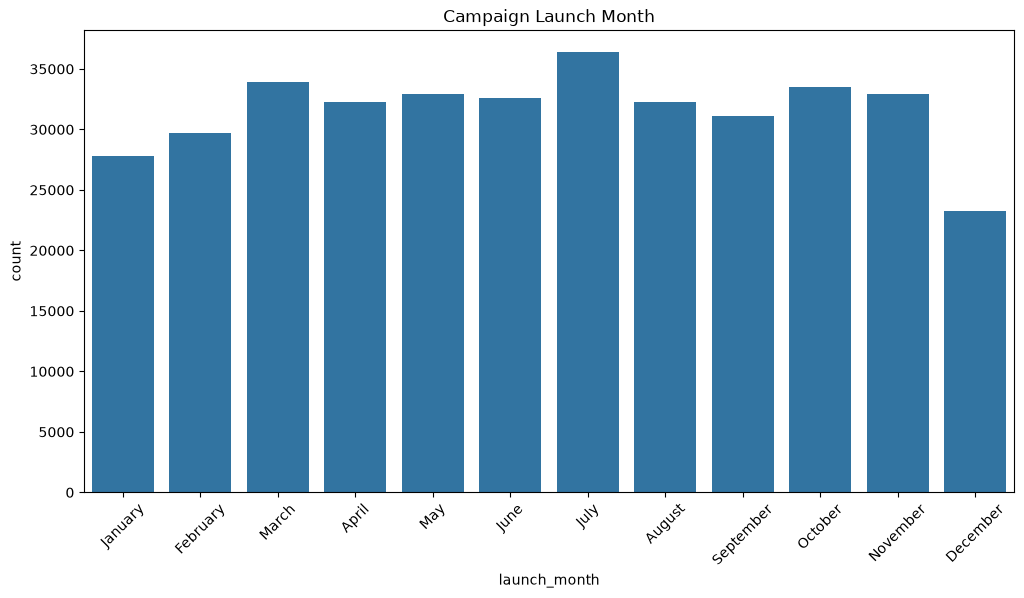

In [337]:
plt.figure(figsize=(12,6))

sns.countplot(
    data=df,
    x="launch_month",
    order=[
        "January","February","March","April",
        "May","June","July","August",
        "September","October","November","December"
    ]
)

plt.xticks(rotation=45)

plt.title("Campaign Launch Month")

plt.show()

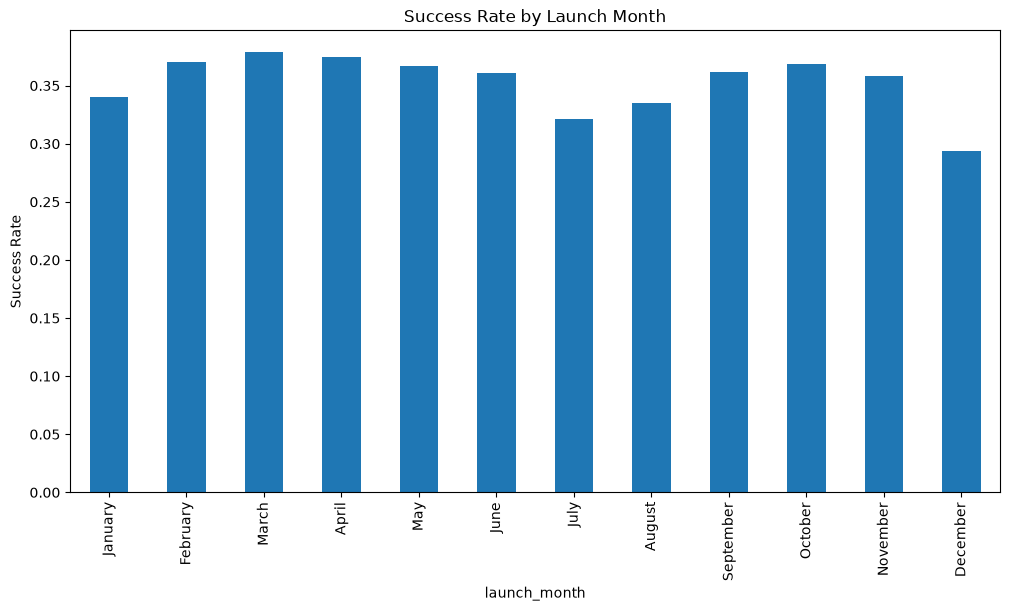

In [338]:
month_success = (
    df
    .groupby("launch_month")["target"]
    .mean()
    .reindex([
        "January","February","March","April",
        "May","June","July","August",
        "September","October","November","December"
    ])
)

month_success.plot(
    kind="bar",
    figsize=(12,6)
)

plt.ylabel("Success Rate")

plt.title("Success Rate by Launch Month")

plt.show()

In [339]:
df["launch_weekday"] = (
    df["launched"]
      .dt.day_name()
)

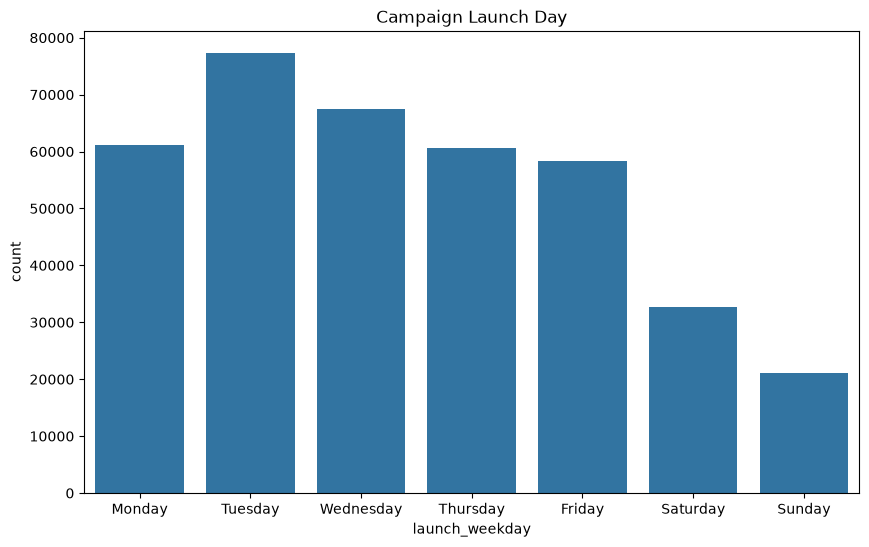

In [340]:
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    x="launch_weekday",
    order=weekday_order
)

plt.title("Campaign Launch Day")

plt.show()

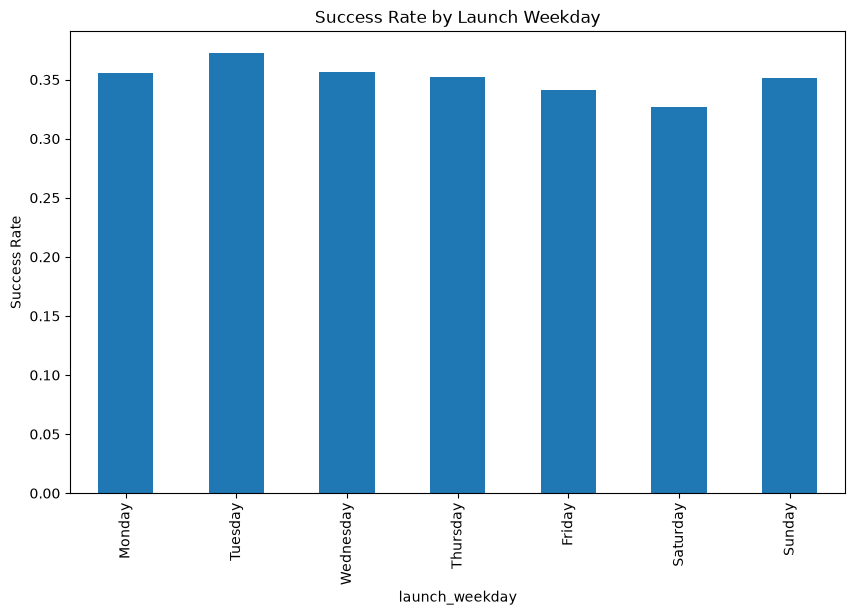

In [341]:
weekday_success = (
    df
    .groupby("launch_weekday")["target"]
    .mean()
    .reindex(weekday_order)
)

weekday_success.plot(
    kind="bar",
    figsize=(10,6)
)

plt.ylabel("Success Rate")

plt.title("Success Rate by Launch Weekday")

plt.show()

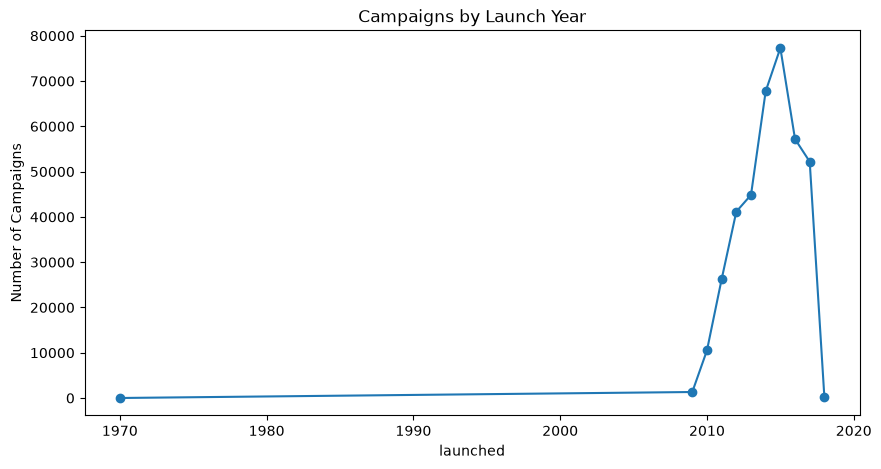

In [342]:
campaigns_per_year = (
    df["launched"]
      .dt.year
      .value_counts()
      .sort_index()
)

campaigns_per_year.plot(
    figsize=(10,5),
    marker="o"
)

plt.title("Campaigns by Launch Year")

plt.ylabel("Number of Campaigns")

plt.show()

In [343]:
df["country"].value_counts()

country
US      292627
GB       33672
CA       14756
AU        7839
DE        4171
N,0"      3797
FR        2939
IT        2878
NL        2868
ES        2276
SE        1757
MX        1752
NZ        1447
DK        1113
IE         811
CH         761
NO         708
HK         618
BE         617
AT         597
SG         555
LU          62
JP          40
Name: count, dtype: int64

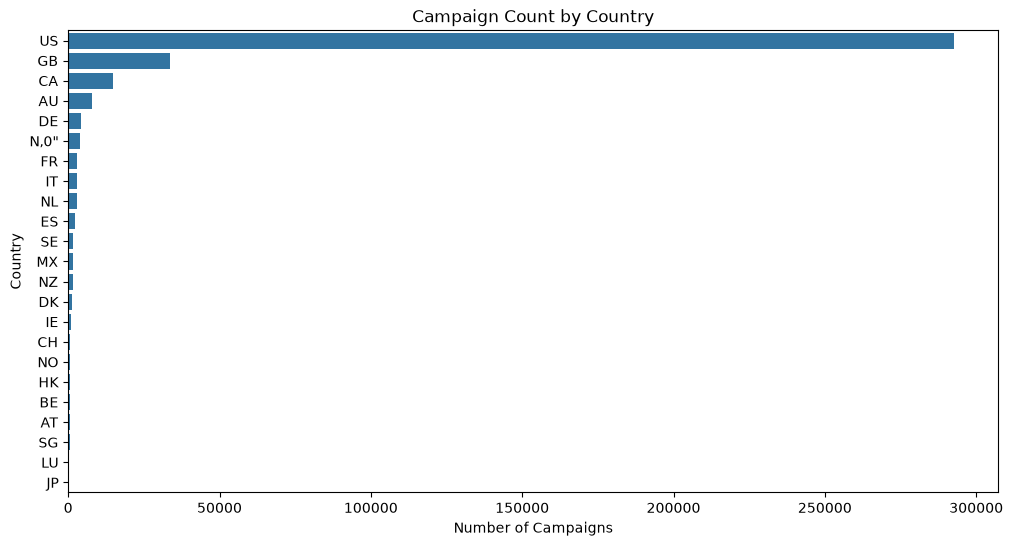

In [344]:
plt.figure(figsize=(12,6))

sns.countplot(
    data=df,
    y="country",
    order=df["country"].value_counts().index
)

plt.title("Campaign Count by Country")

plt.xlabel("Number of Campaigns")

plt.ylabel("Country")

plt.show()

In [345]:
country_percentage = (
    df["country"]
    .value_counts(normalize=True)
    *100
)

country_percentage

country
US      77.279414
GB       8.892387
CA       3.896889
AU       2.070189
DE       1.101513
N,0"     1.002744
FR       0.776156
IT       0.760047
NL       0.757406
ES       0.601065
SE       0.464003
MX       0.462683
NZ       0.382136
DK       0.293930
IE       0.214176
CH       0.200971
NO       0.186975
HK       0.163207
BE       0.162943
AT       0.157661
SG       0.146569
LU       0.016373
JP       0.010564
Name: proportion, dtype: float64

In [346]:
country_success = (
    df
    .groupby("country")["target"]
    .mean()
    .sort_values(ascending=False)
)

country_success

country
US      0.373510
GB      0.358369
HK      0.349515
DK      0.323450
SG      0.320721
NZ      0.309606
FR      0.308949
LU      0.306452
SE      0.289698
CA      0.280157
AU      0.256410
IE      0.255240
BE      0.246353
CH      0.245729
NO      0.228814
MX      0.226027
DE      0.224646
ES      0.216169
NL      0.215132
AT      0.179229
JP      0.175000
IT      0.152536
N,0"    0.027653
Name: target, dtype: float64

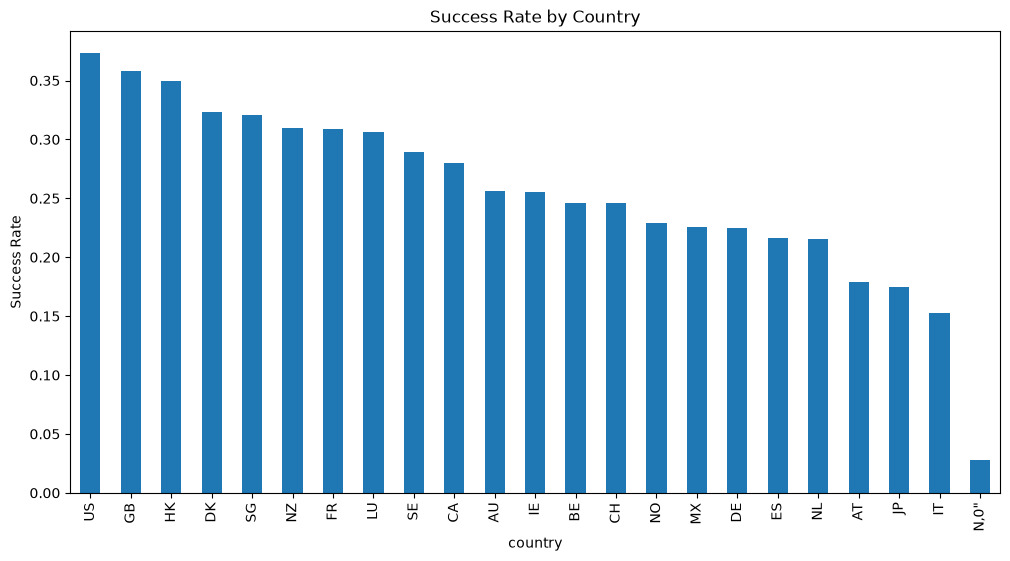

In [347]:
plt.figure(figsize=(12,6))

country_success.plot(
    kind="bar"
)

plt.ylabel("Success Rate")

plt.title("Success Rate by Country")

plt.show()


In [348]:
country_summary = (
    df
    .groupby("country")
    .agg(
        Campaigns=("target","count"),
        Success_Rate=("target","mean")
    )
    .sort_values(
        "Campaigns",
        ascending=False
    )
)

country_summary

,Campaigns,Success_Rate
country,,
US,292627,0.373510
GB,33672,0.358369
CA,14756,0.280157
AU,7839,0.256410
DE,4171,0.224646
"N,0""",3797,0.027653
FR,2939,0.308949
IT,2878,0.152536
NL,2868,0.215132


In [349]:
filtered_country_summary = (
    country_summary[
        country_summary["Campaigns"] >= 100
    ]
)

filtered_country_summary

,Campaigns,Success_Rate
country,,
US,292627,0.373510
GB,33672,0.358369
CA,14756,0.280157
AU,7839,0.256410
DE,4171,0.224646
"N,0""",3797,0.027653
FR,2939,0.308949
IT,2878,0.152536
NL,2868,0.215132


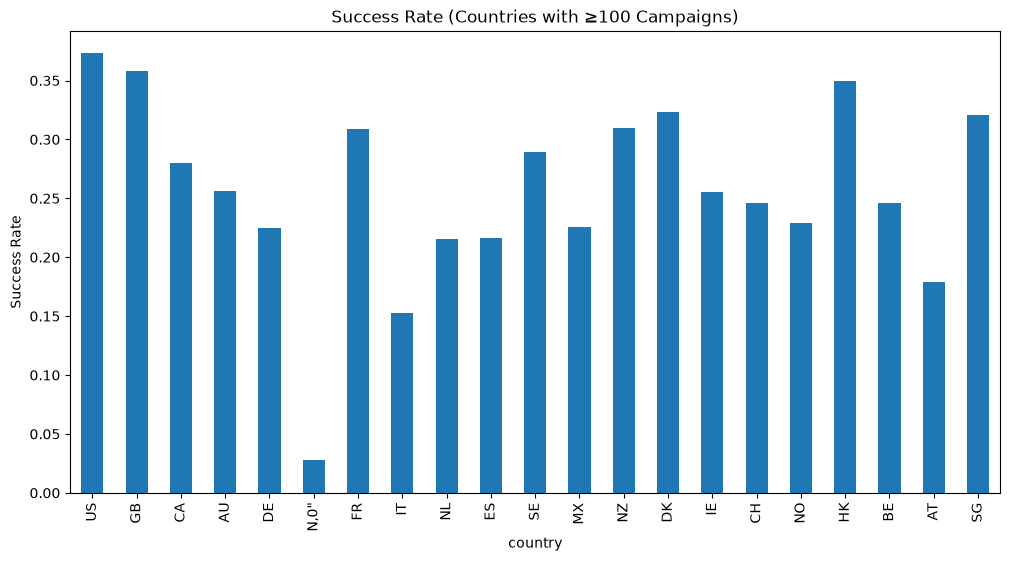

In [350]:
filtered_country_summary["Success_Rate"].plot(
    kind="bar",
    figsize=(12,6)
)

plt.ylabel("Success Rate")

plt.title("Success Rate (Countries with ≥100 Campaigns)")

plt.show()

In [351]:
df["currency"].value_counts()

currency
USD    295365
GBP     34132
EUR     17405
CAD     14962
AUD      7950
SEK      1788
MXN      1752
NZD      1475
DKK      1129
CHF       768
NOK       722
HKD       618
SGD       555
JPY        40
Name: count, dtype: int64

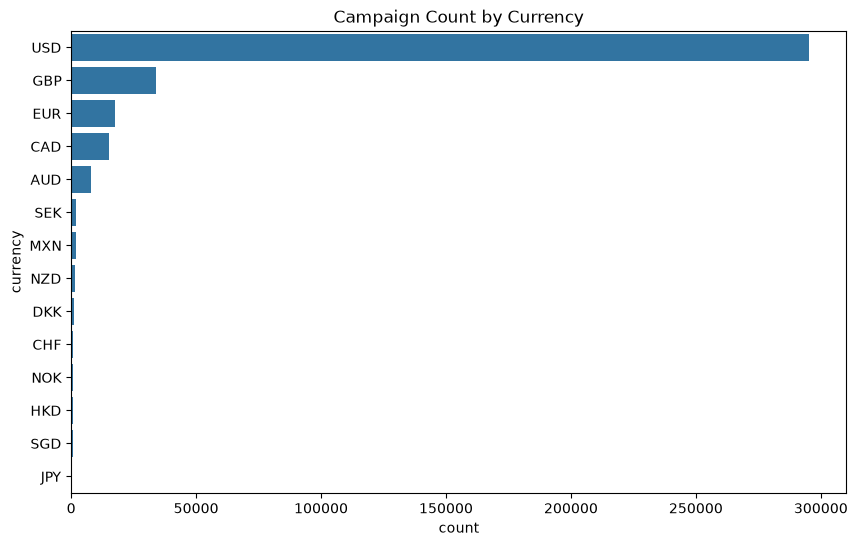

In [352]:
plt.figure(figsize=(10,6))

sns.countplot(
    data=df,
    y="currency",
    order=df["currency"].value_counts().index
)

plt.title("Campaign Count by Currency")

plt.show()

In [353]:
currency_success = (
    df
    .groupby("currency")["target"]
    .mean()
)

currency_success

currency
AUD    0.252956
CAD    0.276500
CHF    0.243490
DKK    0.320638
EUR    0.223039
GBP    0.353949
HKD    0.349515
JPY    0.175000
MXN    0.226027
NOK    0.225762
NZD    0.303729
SEK    0.284676
SGD    0.320721
USD    0.370318
Name: target, dtype: float64

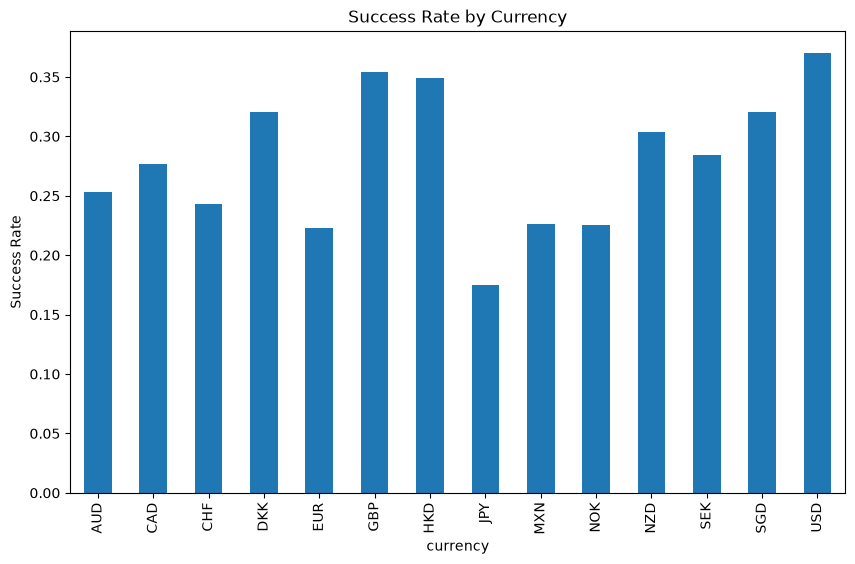

In [354]:
currency_success.plot(
    kind="bar",
    figsize=(10,6)
)

plt.ylabel("Success Rate")

plt.title("Success Rate by Currency")

plt.show()

In [355]:
country_category = pd.crosstab(
    df["country"],
    df["category"]
)

country_category

category,3D Printing,Academic,Accessories,Action,Animals,Animation,Anthologies,Apparel,Apps,Architecture,Art,Art Books,Audio,Bacon,Blues,Calendars,Camera Equipment,Candles,Ceramics,Children's Books,Childrenswear,Chiptune,Civic Design,Classical Music,Comedy,Comic Books,Comics,Community Gardens,Conceptual Art,Cookbooks,Country & Folk,Couture,Crafts,Crochet,DIY,DIY Electronics,Dance,Design,Digital Art,Documentary,Drama,Drinks,Electronic Music,Embroidery,Events,Experimental,Fabrication Tools,Faith,Family,Fantasy,Farmer's Markets,Farms,Fashion,Festivals,Fiction,Film & Video,Fine Art,Flight,Food,Food Trucks,Footwear,Gadgets,Games,Gaming Hardware,Glass,Graphic Design,Graphic Novels,Hardware,Hip-Hop,Horror,Illustration,Immersive,Indie Rock,Installations,Interactive Design,Jazz,Jewelry,Journalism,Kids,Knitting,Latin,Letterpress,Literary Journals,Literary Spaces,Live Games,Makerspaces,Metal,Mixed Media,Mobile Games,Movie Theaters,Music,Music Videos,Musical,Narrative Film,Nature,Nonfiction,Painting,People,Performance Art,Performances,Periodicals,Pet Fashion,Photo,Photobooks,Photography,Places,Playing Cards,Plays,Poetry,Pop,Pottery,Print,Printing,Product Design,Public Art,Publishing,Punk,Puzzles,Quilts,R&B,Radio & Podcasts,Ready-to-wear,Residencies,Restaurants,Robots,Rock,Romance,Science Fiction,Sculpture,Shorts,Small Batch,Software,Sound,Space Exploration,Spaces,Stationery,Tabletop Games,Taxidermy,Technology,Television,Textiles,Theater,Thrillers,Translations,Typography,Vegan,Video,Video Art,Video Games,Wearables,Weaving,Web,Webcomics,Webseries,Woodworking,Workshops,World Music,Young Adult,Zines
country,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
AT,5,1,3,2,0,3,1,17,25,1,14,3,1,0,0,0,2,1,0,4,0,0,0,3,1,1,2,0,2,2,3,0,4,0,1,4,2,14,3,11,1,8,5,1,2,0,2,1,0,1,0,4,9,2,5,7,0,0,16,1,2,15,14,0,0,4,1,12,3,3,3,1,0,4,2,1,4,3,1,0,0,0,0,0,4,0,2,3,6,0,12,3,0,1,2,9,5,4,2,1,4,1,1,8,13,3,6,2,1,2,0,2,0,58,4,10,0,1,0,0,0,1,0,2,5,2,1,0,0,9,5,15,3,0,1,0,10,0,23,1,0,3,0,1,3,1,1,0,28,5,0,17,1,6,6,0,2,1,0
AU,19,22,127,19,11,44,23,258,300,30,137,59,8,9,10,12,11,16,2,157,19,0,7,19,67,70,44,11,16,28,13,7,83,3,27,34,11,137,28,232,72,49,53,4,25,26,11,21,13,13,9,30,166,18,149,102,28,12,197,37,44,100,98,11,0,39,50,102,35,28,65,5,30,11,18,5,43,33,10,2,1,1,7,1,29,8,12,40,106,6,138,22,14,20,28,166,59,37,15,11,13,6,4,56,96,30,102,18,12,43,2,21,5,697,29,160,11,5,2,5,13,47,2,48,11,47,6,24,12,101,24,110,21,11,10,16,274,1,225,28,9,13,33,4,1,14,6,2,336,29,4,248,10,88,17,4,17,26,15
BE,2,3,6,2,1,5,1,18,26,1,3,4,0,0,0,0,1,0,1,2,3,0,3,7,1,3,1,1,0,2,0,2,4,0,9,5,0,18,5,12,3,7,15,0,2,1,2,1,0,0,0,4,10,0,5,8,6,4,9,6,8,2,8,1,0,4,2,5,1,2,11,1,2,3,2,5,4,1,1,1,0,0,1,0,9,2,2,5,7,0,11,0,0,3,3,9,7,4,2,1,1,0,2,4,6,2,4,0,1,2,1,1,2,43,2,13,0,0,0,0,0,3,0,5,1,4,1,1,3,6,1,10,3,1,0,0,21,0,18,0,3,3,0,1,0,0,1,0,48,1,0,19,2,2,4,0,4,2,0
CA,44,50,209,36,18,105,52,361,372,42,307,95,11,20,17,18,23,17,11,264,26,1,13,69,109,168,125,20,22,27,115,11,202,25,74,69,37,233,67,498,66,117,79,2,37,42,25,36,7,20,24,58,261,37,334,179,48,23,402,76,48,173,174,29,3,61,129,186,103,41,164,11,83,21,28,22,83,68,15,14,3,1,16,3,50,19,40,119,124,7,282,40,33,57,29,332,149,57,47,36,32,17,12,72,117,53,133,35,56,88,4,27,10,1119,73,208,19,12,5,10,29,44,2,132,25,126,14,28,65,185,84,156,20,16,35,16,580,0,437,54,14,72,44,8,4,38,25,8,782,79,6,332,63,173,47,13,63,49,30
CH,1,2,23,0,0,4,0,13,47,0,10,3,0,0,1,0,1,0,0,1,1,0,0,7,3,3,2,0,3,2,1,0,7,0,5,1,0,18,2,15,3,10,7,1,1,2,3,0,0,1,1,1,8,1,5,1,1,4,15,3,8,13,5,0,0,4,0,18,3,2,9,0,0,1,1,3,6,0,0,0,1,1,0,0,3,1,3,3,10,2,11,2,1,1,0,7,9,1,2,3,1,0,1,3,7,2,10,1,1,3,0,2,3,108,5,11,0,0,0,0,1,6,0,13,1,6,0,4,1,10,1,25,5,3,4,1,12,0,46,1,2,3,1,1,1,1,1,1,25,6,0,32,0,2,4,0,3,2,0
DE,24,34,44,12,6,13,7,117,160,13,65,19,3,1,1,6,12,3,3,27,8,5,4,14,18,20,18,1,12,13,6,4,52,2,8,22,7,69,12,96,8,33,52,2,17,13,14,3,0,7,1,10,51,3,38,35,8,6,86,9,26,85,66,15,2,39,4,78,24,9,17,3,10,8,5,15,24,15,1,2,1,5,0,0,21,0,19,1

In [356]:
country_outcome = pd.crosstab(
    df["country"],
    df["state"],
    normalize="index"
)

country_outcome

state,canceled,failed,live,successful,suspended,undefined
country,,,,,,
AT,0.152429,0.633166,0.025126,0.179229,0.010050,0.000000
AU,0.135859,0.587575,0.008930,0.256410,0.011226,0.000000
BE,0.119935,0.601297,0.019449,0.246353,0.012966,0.000000
CA,0.144890,0.558146,0.008946,0.280157,0.007861,0.000000
CH,0.110381,0.611038,0.018397,0.245729,0.014455,0.000000
DE,0.148885,0.599137,0.017981,0.224646,0.009350,0.000000
DK,0.141060,0.508535,0.014376,0.323450,0.012579,0.000000
ES,0.145431,0.606766,0.022847,0.216169,0.008787,0.000000
FR,0.120109,0.548486,0.017693,0.308949,0.004764,0.000000


In [357]:
rare_countries = (
    df["country"]
    .value_counts()
)

rare_countries[
    rare_countries < 20
]

Series([], Name: count, dtype: int64)

In [358]:
# This dataset (ks-projects-201801) has only one text column: `name`.
# There is no `desc` column, so text intelligence is built on the campaign title.
text_columns = ["name"]

df[text_columns].isnull().sum()

name    4
dtype: int64

In [359]:
# Count effectively-empty titles (null or whitespace-only)
(df["name"].fillna("").str.strip() == "").sum()

np.int64(4)

In [360]:
# ============================================================
# PART E - TEXT INTELLIGENCE  (campaign title `name`)
# ============================================================

# Title-based text features
df["name_length"]     = df["name"].fillna("").apply(len)
df["word_count"]      = df["name"].fillna("").apply(lambda x: len(x.split()))
df["has_number"]      = df["name"].fillna("").str.contains(r"\d", regex=True).astype(int)
df["has_exclamation"] = df["name"].fillna("").str.contains("!", regex=False).astype(int)
df["has_question"]    = df["name"].fillna("").str.contains(r"\?", regex=True).astype(int)

# Mean title metrics by outcome (decided campaigns only)
decided = df[df["state"].isin(["successful", "failed"])]

decided.groupby("state")[["name_length", "word_count"]].mean().round(2)

,name_length,word_count
state,,
failed,32.85,5.37
successful,36.24,6.01


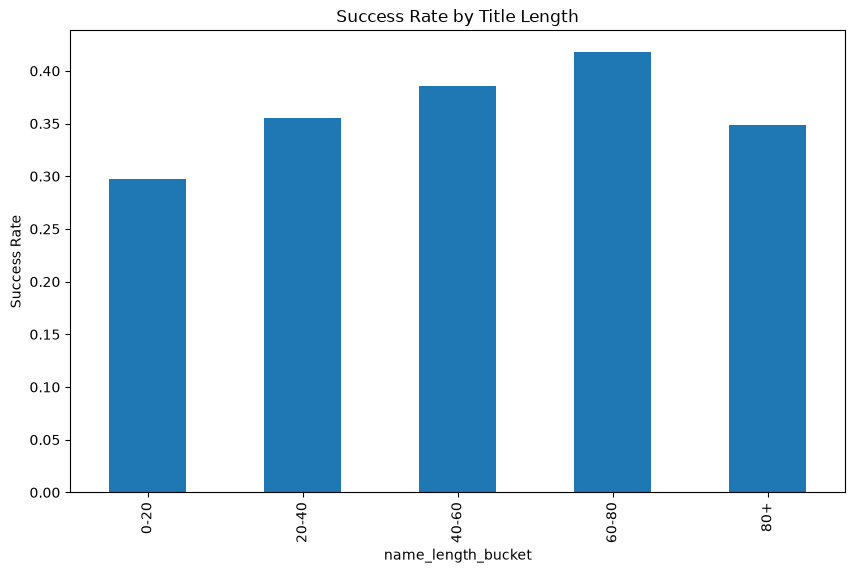

name_length_bucket
0-20     0.297512
20-40    0.355547
40-60    0.385661
60-80    0.417537
80+      0.348665
Name: target, dtype: float64

In [361]:
# Success rate by title-length bucket
length_bins   = [0, 20, 40, 60, 80, np.inf]
length_labels = ["0-20", "20-40", "40-60", "60-80", "80+"]

df["name_length_bucket"] = pd.cut(
    df["name_length"],
    bins=length_bins,
    labels=length_labels
)

name_length_success = (
    df
    .groupby("name_length_bucket", observed=True)["target"]
    .mean()
)

name_length_success.plot(kind="bar", figsize=(10, 6))
plt.ylabel("Success Rate")
plt.title("Success Rate by Title Length")
plt.show()

name_length_success

In [362]:
# Do title signals (numbers / punctuation) relate to success?
signal_prevalence = (
    df
    .groupby("state")[["has_number", "has_exclamation", "has_question"]]
    .mean()
    .round(3)
)

# Success rate conditioned on each signal (decided campaigns only)
signal_success = {
    signal: decided.groupby(signal)["target"].mean().round(3).to_dict()
    for signal in ["has_number", "has_exclamation", "has_question"]
}

print("Signal prevalence by outcome:")
print(signal_prevalence)
print("\nSuccess rate by signal (0 = absent, 1 = present):")
for name, rates in signal_success.items():
    print(f"  {name}: {rates}")

Signal prevalence by outcome:
            has_number  has_exclamation  has_question
state                                                
canceled         0.102            0.084         0.009
failed           0.091            0.081         0.009
live             0.111            0.068         0.008
successful       0.136            0.111         0.008
suspended        0.126            0.105         0.011
undefined        0.104            0.103         0.008

Success rate by signal (0 = absent, 1 = present):
  has_number: {0: 0.392, 1: 0.503}
  has_exclamation: {0: 0.396, 1: 0.483}
  has_question: {0: 0.404, 1: 0.377}


In [363]:
# ============================================================
# PART F - SUCCESS & FAILURE ARCHETYPES
# ============================================================

decided = df[df["state"].isin(["successful", "failed"])].copy()

profile_features = [
    "goal", "usd_goal_real", "backers",
    "campaign_duration", "name_length", "word_count"
]

# Typical (median) profile of a successful vs a failed campaign
archetype_numeric = (
    decided
    .groupby("state")[profile_features]
    .median()
    .round(2)
)

archetype_numeric

,goal,usd_goal_real,backers,campaign_duration,name_length,word_count
state,,,,,,
failed,7500.0,7500.00,3.0,29.0,31.0,5.0
successful,3923.0,3837.74,71.0,29.0,36.0,6.0


In [364]:
# Most representative category / country / goal-band for each outcome
def top_value(frame, col):
    return frame[col].value_counts().idxmax()

archetypes = {}
for outcome in ["successful", "failed"]:
    sub = decided[decided["state"] == outcome]
    archetypes[outcome] = {
        "top_category":     top_value(sub, "main_category"),
        "top_country":      top_value(sub, "country"),
        "top_goal_band":    top_value(sub, "goal_bucket"),
        "median_goal_usd":  round(sub["usd_goal_real"].median(), 2),
        "median_backers":   int(sub["backers"].median()),
        "median_duration":  int(sub["campaign_duration"].median()),
        "median_title_len": int(sub["name_length"].median()),
    }

archetype_summary = pd.DataFrame(archetypes).T
archetype_summary

,top_category,top_country,top_goal_band,median_goal_usd,median_backers,median_duration,median_title_len
successful,Music,US,1K-5K,3837.74,71,29,36
failed,Film & Video,US,1K-5K,7500.0,3,29,31


In [365]:
# ============================================================
# PART G - VENTURE HYPOTHESIS LOG
# ============================================================
# Structured log of the descriptive findings from Parts A-F.
# Each row is a testable hypothesis with a confidence level and the
# modeling step that would confirm or refute it.

hypotheses = [
    {
        "id": "H1",
        "area": "Category Intelligence",
        "hypothesis": "Creative/performance categories (Dance, Theater, Comics, Music) "
                      "succeed far more often than product/hardware ones (Technology, Food).",
        "evidence": "Success rate 65% (Dance) vs 24% (Technology) on decided campaigns.",
        "confidence": "Medium",
        "future_validation": "Logistic Regression coefficients; SHAP; Pattern Mining",
    },
    {
        "id": "H2",
        "area": "Funding Goal Intelligence",
        "hypothesis": "Higher funding goals reduce success probability.",
        "evidence": "Median goal of failed (7,500) > successful (3,923); goal ~ -0.03 corr.",
        "confidence": "Medium",
        "future_validation": "Logistic Regression on log(goal); SHAP dependence plot",
    },
    {
        "id": "H3",
        "area": "Campaign Timing Intelligence",
        "hypothesis": "Launch month and weekday affect success rate.",
        "evidence": "Success rate varies across launch_month / launch_weekday buckets.",
        "confidence": "Low-Medium",
        "future_validation": "Add temporal features; test coefficient significance",
    },
    {
        "id": "H4",
        "area": "Geographic Intelligence",
        "hypothesis": "Success rate differs by country/currency in this US-centric dataset.",
        "evidence": "Country-level success rates differ; ~78% of campaigns are US/USD.",
        "confidence": "Low",
        "future_validation": "Encode country; control for category mix; SHAP",
    },
    {
        "id": "H5",
        "area": "Text Intelligence",
        "hypothesis": "Longer titles and numeric/'!' signals carry weak positive signal.",
        "evidence": "Successful titles avg 36 chars vs 33; has_number +11pts success.",
        "confidence": "Low",
        "future_validation": "NLP embeddings; logistic regression; SHAP",
    },
    {
        "id": "H6",
        "area": "Archetypes",
        "hypothesis": "A 'successful archetype' (lower goal, more backers) is distinguishable "
                      "from a 'failed archetype'.",
        "evidence": "Median goal/backers differ clearly by outcome (Part F).",
        "confidence": "Medium",
        "future_validation": "Clustering; classification model; counterfactual analysis",
    },
]

hypothesis_log = pd.DataFrame(hypotheses)
hypothesis_log

,id,area,hypothesis,evidence,confidence,future_validation
0,H1,Category Intelligence,"Creative/performance categories (Dance, Theater, Comics, Music) succeed far more often than prod...",Success rate 65% (Dance) vs 24% (Technology) on decided campaigns.,Medium,Logistic Regression coefficients; SHAP; Pattern Mining
1,H2,Funding Goal Intelligence,Higher funding goals reduce success probability.,"Median goal of failed (7,500) > successful (3,923); goal ~ -0.03 corr.",Medium,Logistic Regression on log(goal); SHAP dependence plot
2,H3,Campaign Timing Intelligence,Launch month and weekday affect success rate.,Success rate varies across launch_month / launch_weekday buckets.,Low-Medium,Add temporal features; test coefficient significance
3,H4,Geographic Intelligence,Success rate differs by country/currency in this US-centric dataset.,Country-level success rates differ; ~78% of campaigns are US/USD.,Low,Encode country; control for category mix; SHAP
4,H5,Text Intelligence,Longer titles and numeric/'!' signals carry weak positive signal.,Successful titles avg 36 chars vs 33; has_number +11pts success.,Low,NLP embeddings; logistic regression; SHAP
5,H6,Archetypes,"A 'successful archetype' (lower goal, more backers) is distinguishable from a 'failed archetype'.",Median goal/backers differ clearly by outcome (Part F).,Medium,Clustering; classification model; counterfactual analysis


In [366]:
# Compact view of the hypothesis log
hypothesis_log[["id", "area", "confidence", "hypothesis"]]

,id,area,confidence,hypothesis
0,H1,Category Intelligence,Medium,"Creative/performance categories (Dance, Theater, Comics, Music) succeed far more often than prod..."
1,H2,Funding Goal Intelligence,Medium,Higher funding goals reduce success probability.
2,H3,Campaign Timing Intelligence,Low-Medium,Launch month and weekday affect success rate.
3,H4,Geographic Intelligence,Low,Success rate differs by country/currency in this US-centric dataset.
4,H5,Text Intelligence,Low,Longer titles and numeric/'!' signals carry weak positive signal.
5,H6,Archetypes,Medium,"A 'successful archetype' (lower goal, more backers) is distinguishable from a 'failed archetype'."


In [367]:
# Persist the hypothesis log for the reports / knowledge-base layers
import os

os.makedirs("../outputs/reports", exist_ok=True)

hypothesis_log.to_csv(
    "../outputs/reports/venture_hypotheses.csv",
    index=False
)

print("Saved venture_hypotheses.csv with", len(hypothesis_log), "hypotheses.")

Saved venture_hypotheses.csv with 6 hypotheses.


In [368]:
missing = (
    df.isnull()
      .sum()
      .to_frame("Missing_Count")
)

missing["Missing_%"] = (
    missing["Missing_Count"]
    / len(df)
) * 100

missing = missing.sort_values(
    "Missing_%",
    ascending=False
)

missing

,Missing_Count,Missing_%
usd pledged,3797,1.002744
duration_bucket,102,0.026937
name_length_bucket,4,0.001056
name,4,0.001056
word_count,0,0.000000
has_question,0,0.000000
has_exclamation,0,0.000000
has_number,0,0.000000
launch_weekday,0,0.000000
launch_month_num,0,0.000000


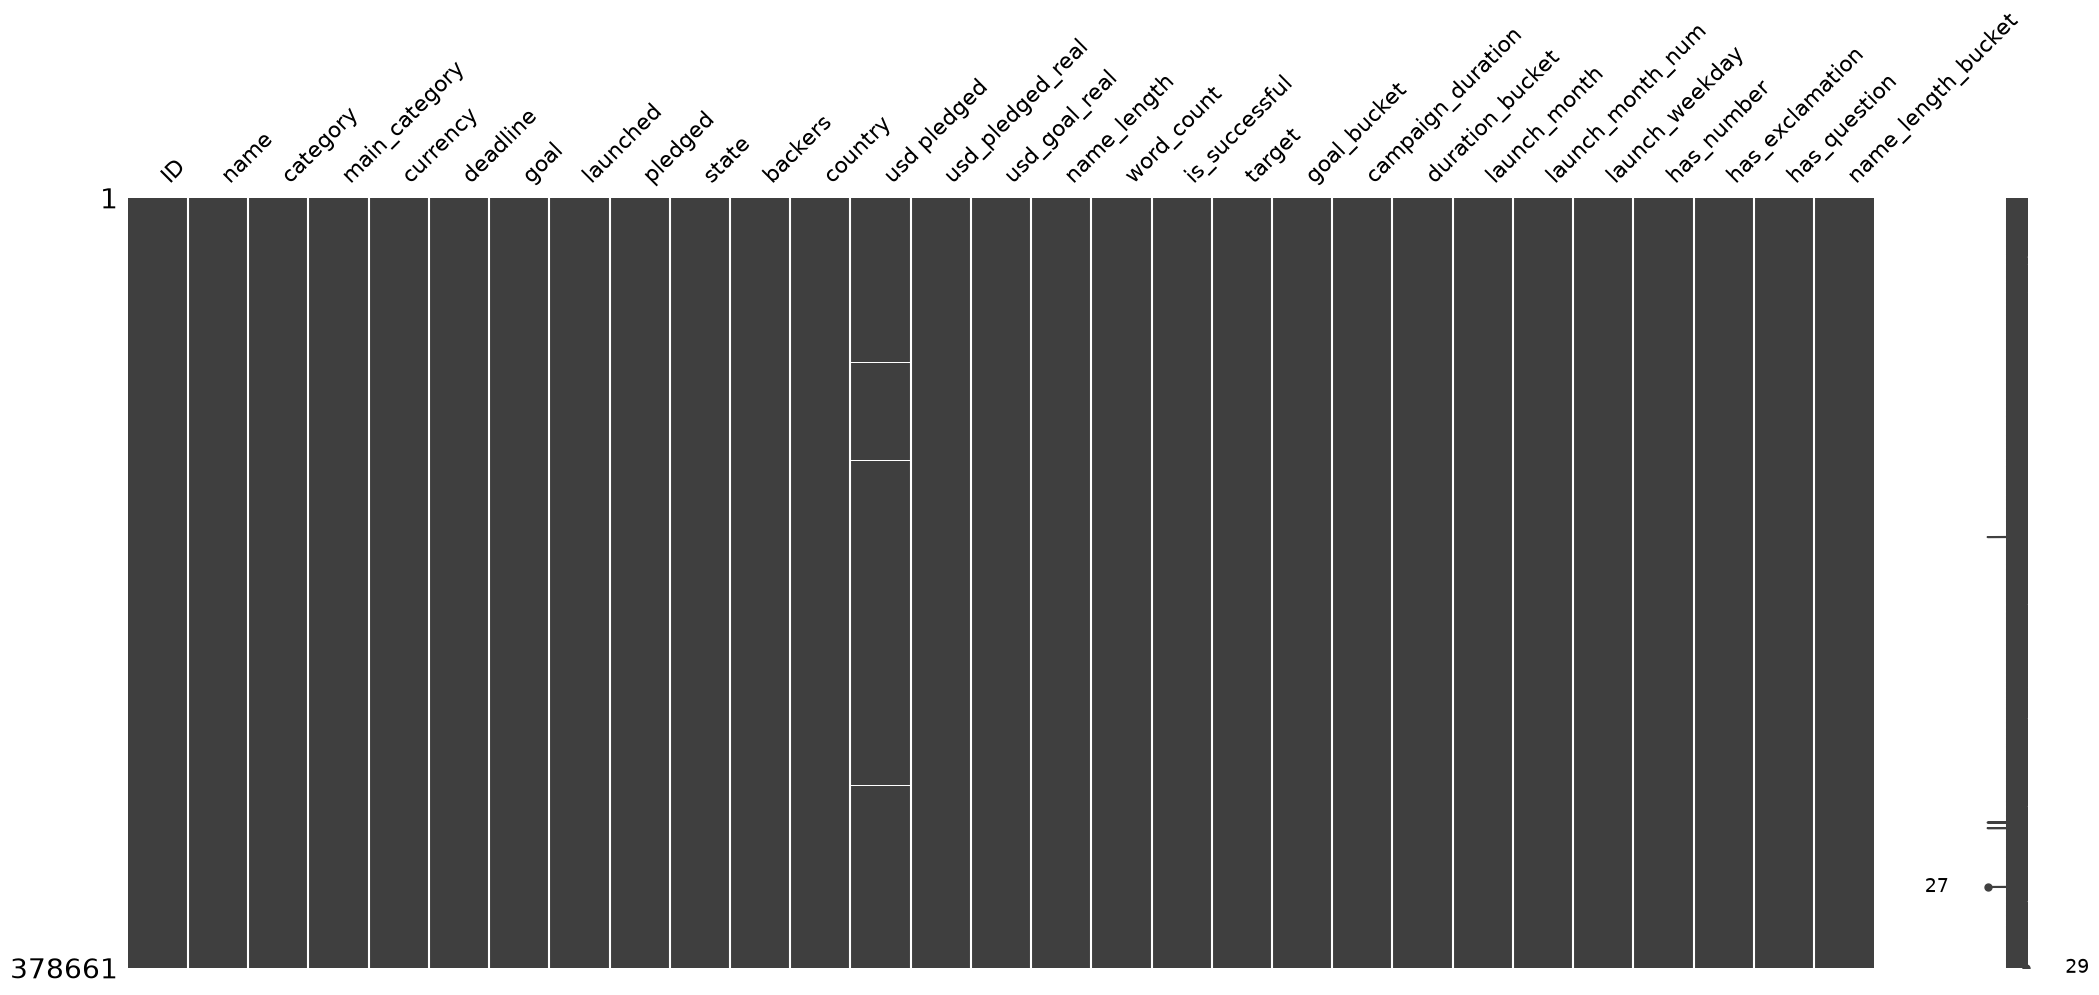

In [369]:
import missingno as msno

msno.matrix(df)
plt.show()


In [370]:
duplicates = df.duplicated().sum()

duplicates

np.int64(0)

In [371]:
df["ID"].duplicated().sum()

np.int64(0)

In [372]:
df.dtypes

ID                             int64
name                             str
category                         str
main_category                    str
currency                         str
deadline              datetime64[us]
goal                         float64
launched              datetime64[us]
pledged                      float64
state                            str
backers                        int64
country                          str
usd pledged                  float64
usd_pledged_real             float64
usd_goal_real                float64
name_length                    int64
word_count                     int64
is_successful                  int64
target                         int64
goal_bucket                 category
campaign_duration              int64
duration_bucket             category
launch_month                     str
launch_month_num               int32
launch_weekday                   str
has_number                     int64
has_exclamation                int64
h

In [373]:
datatype_summary = pd.DataFrame({
    "Column": df.columns,
    "DataType": df.dtypes.astype(str)
})

datatype_summary

,Column,DataType
ID,ID,int64
name,name,str
category,category,str
main_category,main_category,str
currency,currency,str
deadline,deadline,datetime64[us]
goal,goal,float64
launched,launched,datetime64[us]
pledged,pledged,float64
state,state,str


In [374]:
constant_columns = [
    col
    for col in df.columns
    if df[col].nunique() == 1
]

constant_columns

[]

In [375]:
cardinality = (
    df.nunique()
      .sort_values(
          ascending=False
      )
)

cardinality

ID                    378661
launched              378089
name                  375764
usd_pledged_real      106065
usd pledged            95455
pledged                62130
usd_goal_real          50339
goal                    8353
backers                 3963
deadline                3164
category                 159
campaign_duration         99
name_length               97
word_count                24
country                   23
main_category             15
currency                  14
launch_month_num          12
launch_month              12
launch_weekday             7
goal_bucket                7
state                      6
duration_bucket            6
name_length_bucket         5
is_successful              2
has_number                 2
has_exclamation            2
has_question               2
target                     2
dtype: int64

In [376]:
numeric_cols = df.select_dtypes(include="number").columns

for col in numeric_cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1

    outliers = (
        (
            df[col] < q1 - 1.5 * iqr
        ) |
        (
            df[col] > q3 + 1.5 * iqr
        )
    ).sum()

    print(col, outliers)

ID 0
goal 46613
pledged 50981
backers 45343
usd pledged 50919
usd_pledged_real 50578
usd_goal_real 45508
name_length 57
word_count 157
is_successful 0
target 0
campaign_duration 76973
launch_month_num 0
has_number 41063
has_exclamation 34909
has_question 3359


In [377]:
missing_summary = (
    df.isnull()
      .sum()
      .to_frame(name="Missing_Count")
)

missing_summary["Missing_Percentage"] = (
    missing_summary["Missing_Count"] / len(df)
) * 100

missing_summary = (
    missing_summary
    .sort_values(
        by="Missing_Percentage",
        ascending=False
    )
)

missing_summary

,Missing_Count,Missing_Percentage
usd pledged,3797,1.002744
duration_bucket,102,0.026937
name_length_bucket,4,0.001056
name,4,0.001056
word_count,0,0.000000
has_question,0,0.000000
has_exclamation,0,0.000000
has_number,0,0.000000
launch_weekday,0,0.000000
launch_month_num,0,0.000000
